<a href="https://colab.research.google.com/github/IRay3477/Pengembangan-Model-Deep-Learning-dan-Implementasi-API/blob/main/Deep_Learning_Peringkasan_Otomatis_Video_Kuliah_Bahasa_Indonesia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tahap 1: Profiling dataset + uji terjemahan

In [1]:
!pip -q install transformers sentencepiece sacremoses rouge-score

import os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from collections import Counter
from rouge_score import rouge_scorer
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import gc
import sentencepiece as spm
from huggingface_hub import hf_hub_download
from transformers import Seq2SeqTrainer, Seq2SeqTrainingArguments, BatchEncoding

drive.mount('/content/drive')

# Semua path diatur di sini, kalau folder pindah cukup ubah folder_utama
folder_utama = '/content/drive/MyDrive/DEEP_LEARNING_test'
csv_path = f'{folder_utama}/Dataset/ak_lectures_summarized.csv'

output_tahap1 = f'{folder_utama}/tahap1'
output_tahap2 = f'{folder_utama}/tahap2'
output_tahap3 = f'{folder_utama}/tahap3'
output_tahap4 = f'{folder_utama}/tahap4'

os.makedirs(output_tahap1, exist_ok=True)
os.makedirs(output_tahap2, exist_ok=True)
os.makedirs(output_tahap3, exist_ok=True)
os.makedirs(output_tahap4, exist_ok=True)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive


## **Cek Hasil di Drive**
Proses yang hasilnya sudah tersimpan di Drive tidak dijalankan ulang, hasilnya cukup dibaca.
Kalau ingin menjalankan ulang suatu proses, hapus file Drive-nya lalu jalankan ulang cell ini.

In [2]:
path_uji_terjemahan = f'{output_tahap1}/uji_terjemahan_3model.csv'
path_data_id = f'{output_tahap3}/data_clean_id.csv'
path_prediksi_zeroshot = f'{output_tahap4}/prediksi_zeroshot_test.csv'
path_hasil_seleksi = f'{folder_utama}/tahap5/hasil_seleksi_model.csv'

uji_terjemahan_selesai = os.path.exists(path_uji_terjemahan)
tahap3_selesai = os.path.exists(path_data_id)
zeroshot_selesai = os.path.exists(path_prediksi_zeroshot)

status_drive = pd.DataFrame([
    {'proses': 'Uji 3 model translasi (Tahap 1)', 'sudah_ada': uji_terjemahan_selesai, 'file': path_uji_terjemahan},
    {'proses': 'Translasi penuh + perbaikan (Tahap 3)', 'sudah_ada': tahap3_selesai, 'file': path_data_id},
    {'proses': 'Prediksi zero-shot (Tahap 4)', 'sudah_ada': zeroshot_selesai, 'file': path_prediksi_zeroshot},
    {'proses': 'Seleksi model (Tahap 5)', 'sudah_ada': os.path.exists(path_hasil_seleksi), 'file': path_hasil_seleksi},
])
display(status_drive)

,proses,sudah_ada,file
0,Uji 3 model translasi (Tahap 1),False,/content/drive/MyDrive/DEEP_LEARNING_test/taha...
1,Translasi penuh + perbaikan (Tahap 3),False,/content/drive/MyDrive/DEEP_LEARNING_test/taha...
2,Prediksi zero-shot (Tahap 4),False,/content/drive/MyDrive/DEEP_LEARNING_test/taha...
3,Seleksi model (Tahap 5),False,/content/drive/MyDrive/DEEP_LEARNING_test/taha...


## 1. Load data

In [3]:
df = pd.read_csv(csv_path)
print('Ukuran data:', df.shape)

print('=' * 30)
print('Tipe data tiap kolom')
print('=' * 30)
print(df.dtypes)

df.head(3)

Ukuran data: (1871, 7)
Tipe data tiap kolom
Unnamed: 0             int64
Course Name           object
Chapter               object
Video Name            object
Youtube Video Link    object
Summary               object
Transcript            object
dtype: object


,Unnamed: 0,Course Name,Chapter,Video Name,Youtube Video Link,Summary,Transcript
0,0,Biology,Immune System,Introduction to Immune System,https://www.youtube.com/embed/bW-eEBxJYaM?enab...,Instead of being localized at a specific organ...,"Unlike most other systems of our body, the im..."
1,1,Biology,Immune System,Leukocytes of Immune System,https://www.youtube.com/embed/ZQSzIOMRZMQ?enab...,"Leukocytes, or white blood cells, are the cell...","Lucocytes, also known as white blood cells, a..."
2,2,Biology,Immune System,Innate (Non-specific) Immune System,https://www.youtube.com/embed/os1oh8AprYw?enab...,Our innate immune system consists of non-speci...,Our immune system consists of two divisions. ...


## 2. Pilih kolom

Variabel di bawah hanya menyimpan **nama kolom** (string), supaya nama kolom tidak diketik berulang-ulang. Jadi `df[kolom_transkrip]` sama persis dengan `df['Transcript']`.

- `kolom_transkrip` → input model (teks yang akan diringkas)
- `kolom_ringkasan` → target/label (ringkasan referensi)
- `kolom_video` → penanda unik tiap video, untuk cek apakah ada video yang muncul lebih dari sekali

In [4]:
kolom_transkrip = 'Transcript'
kolom_ringkasan = 'Summary'
kolom_video = 'Youtube Video Link'

# 'Unnamed: 0' cuma nomor index lama yang ikut tersimpan di CSV
df = df.drop(columns=['Unnamed: 0'])

print('Video unik:', df[kolom_video].nunique(), 'dari', len(df), 'baris')
print('\nJumlah video per course:')
print(df['Course Name'].value_counts())

Video unik: 1871 dari 1871 baris

Jumlah video per course:
Course Name
Classical physics    638
Organic chemistry    318
Biochemistry         293
Biology              250
Modern physics       232
General chemistry    140
Name: count, dtype: int64


## 3. Kualitas data

### 3.1 Jumlah nilai kosong
Dicek dua jenis kosong: `NaN` (sel benar-benar kosong) dan string yang isinya hanya spasi.

In [5]:
print('NaN per kolom:')
print(df.isna().sum())

print('\nDetail kolom teks:')
for kolom in [kolom_transkrip, kolom_ringkasan]:
    jumlah_nan = df[kolom].isna().sum()
    jumlah_spasi = (df[kolom].notna() & (df[kolom].str.strip() == '')).sum()
    print(f'{kolom}: NaN = {jumlah_nan}, hanya spasi = {jumlah_spasi}')

NaN per kolom:
Course Name            0
Chapter                0
Video Name             0
Youtube Video Link     0
Summary               12
Transcript            17
dtype: int64

Detail kolom teks:
Transcript: NaN = 17, hanya spasi = 0
Summary: NaN = 12, hanya spasi = 0


### 3.2 Contoh baris dengan transkrip kosong

In [6]:
transkrip_kosong = df[df[kolom_transkrip].isna()]
print('Jumlah baris transkrip kosong:', len(transkrip_kosong))
transkrip_kosong[['Course Name', 'Chapter', 'Video Name', kolom_transkrip, kolom_ringkasan]].head(10)

Jumlah baris transkrip kosong: 17


,Course Name,Chapter,Video Name,Transcript,Summary
20,Biology,Immune System,Autoimmunity,NaN,Our immune system displays a natural immunolog...
94,Biology,Genetics,DNA Replication: Helicase and Unwinding,NaN,"Before DNA replication actually begins, a spec..."
95,Biology,Genetics,DNA Replication: Leading and Lagging Strand,NaN,Once DNA helicase binds to the origin of repli...
101,Biology,Genetics,Translation: Ribosomes and Initiation,NaN,Ribosomes are the machinery of biological cell...
102,Biology,Genetics,Translation: Elongation and Termination,NaN,"Following initiation, the ribosome moves on to..."
423,Organic chemistry,Alkenes and Alkynes,Cis-Trans/Z-E Isomer Stability,NaN,Cis or Z isomers are less stable and higher in...
463,Organic chemistry,Substitution and Elimination Reactions,Alkylation: Application of Sn2,NaN,"In this lecture, I discuss a biochemical appli..."
471,Organic chemistry,Substitution and Elimination Reactions,"E1 Reaction: Elimination, Unimolecular",NaN,"In this lecture, I go over the Elimination, Un..."
474,Organic chemistry,Substitution and Elimination Reactions,"E2 Reaction: Elimination, Bimolecular",NaN,"In this lecture, I discuss the E2 reaction and..."
816,Biochemistry,Enzymes,Catalytic Efficiency of Enzymes (kcat/Km),NaN,One way to measure the catalytic efficiency of...


### 3.3 Contoh baris dengan ringkasan kosong

In [7]:
ringkasan_kosong = df[df[kolom_ringkasan].isna()]
print('Jumlah baris ringkasan kosong:', len(ringkasan_kosong))
ringkasan_kosong[['Course Name', 'Chapter', 'Video Name', kolom_transkrip, kolom_ringkasan]].head(10)

Jumlah baris ringkasan kosong: 12


,Course Name,Chapter,Video Name,Transcript,Summary
493,Organic chemistry,Addition Reactions,Dimerization and Polymerization,So let's recall what a hydrohalgenation react...,NaN
989,Biochemistry,Amino Acid Metabolism,Proteasome complex,So once we attach many ubiquitin molecules on...,NaN
990,Biochemistry,Amino Acid Metabolism,Deamination of Amino Acids,Once proteins are broken down into their indi...,NaN
991,Biochemistry,Amino Acid Metabolism,Glucose-alanine cycle,Although our liver is responsible for the maj...,NaN
992,Biochemistry,Amino Acid Metabolism,Urea cycle,So at last let's discuss the urea cycle. So w...,NaN
993,Biochemistry,Amino Acid Metabolism,Defects in Urea Cycle and Hyperammonemia,"Whenever our cells break down amino acids, th...",NaN
994,Biochemistry,Amino Acid Metabolism,Introduction to glucogenic and ketogenic amino...,When we break down amino acids inside our liv...,NaN
995,Biochemistry,Amino Acid Metabolism,Metabolism of Amino Acids to Pyruvate,6. Adet wantumino acids can readily be metabo...,NaN
996,Biochemistry,Amino Acid Metabolism,Metabolism of Amino Acids to Ketoglutarate,"Previously, we saw how we can transform six o...",NaN
997,Biochemistry,Amino Acid Metabolism,Metabolism of Methionine,"Three of the 21 amino acids, namely valine, m...",NaN


### 3.4 Apakah ada baris yang kosong di dua kolom sekaligus?

In [8]:
pd.crosstab(df[kolom_transkrip].isna(), df[kolom_ringkasan].isna(),
            rownames=['transkrip kosong'], colnames=['ringkasan kosong'])

ringkasan kosong,False,True
transkrip kosong,,
False,1842,12
True,17,0


### 3.5 Duplikat transkrip

Hanya dicek pada baris yang **tidak kosong**. Kalau baris kosong ikut dihitung, semua sel kosong dianggap "sama" sehingga jumlah duplikat jadi terlihat lebih besar dari aslinya.

In [9]:
transkrip_terisi = df[df[kolom_transkrip].notna()]
duplikat_transkrip = transkrip_terisi[transkrip_terisi[kolom_transkrip].str.strip().duplicated(keep=False)]

print('Baris dengan transkrip duplikat:', len(duplikat_transkrip))
duplikat_transkrip.sort_values(kolom_transkrip)[['Course Name', 'Chapter', 'Video Name', kolom_video]].head(20)

Baris dengan transkrip duplikat: 0


,Course Name,Chapter,Video Name,Youtube Video Link


### 3.6 Duplikat ringkasan

Baris dengan ringkasan yang sama diberi `nomor_grup` yang sama. Karena transkripnya berbeda (lihat 3.5), ringkasan yang sama berarti minimal satu baris di grup itu labelnya tidak cocok dengan transkripnya.

In [10]:
ringkasan_terisi = df[df[kolom_ringkasan].notna()].copy()
ringkasan_terisi['ringkasan_rapi'] = ringkasan_terisi[kolom_ringkasan].str.strip()

duplikat_ringkasan = ringkasan_terisi[ringkasan_terisi['ringkasan_rapi'].duplicated(keep=False)].copy()
duplikat_ringkasan['nomor_grup'] = duplikat_ringkasan.groupby('ringkasan_rapi').ngroup()
duplikat_ringkasan['awal_ringkasan'] = duplikat_ringkasan[kolom_ringkasan].str[:80] + '...'

print('Baris dengan ringkasan duplikat:', len(duplikat_ringkasan))
print('Jumlah grup ringkasan yang sama:', duplikat_ringkasan['nomor_grup'].nunique())
duplikat_ringkasan.sort_values('nomor_grup')[['nomor_grup', 'Course Name', 'Chapter', 'Video Name', 'awal_ringkasan']].head(20)

Baris dengan ringkasan duplikat: 96
Jumlah grup ringkasan yang sama: 48


,nomor_grup,Course Name,Chapter,Video Name,awal_ringkasan
136,0,Biology,Genetics,Aneuploidy and Nondisjunction (Part II),A karyotype is a pictorial representation of a...
135,0,Biology,Genetics,Aneuploidy and Nondisjunction,A karyotype is a pictorial representation of a...
385,1,General chemistry,Electrochemistry,Neuron Cells (Part I),"A neuron, also called a nerve cell, is a speci..."
386,1,General chemistry,Electrochemistry,Neuron Cells (Part II),"A neuron, also called a nerve cell, is a speci..."
134,2,Biology,Genetics,Pedigree Analysis for Autosomal Dominant Trait...,A third mode of inheritance is called autosoma...
133,2,Biology,Genetics,Pedigree Analysis for Autosomal Dominant Traits,A third mode of inheritance is called autosoma...
18,3,Biology,Immune System,ABO Blood Types (Part II),Another important group of antigens that can a...
19,3,Biology,Immune System,Rh Factor and Rh Incompatibility,Another important group of antigens that can a...
841,4,Biochemistry,Enzymes,Covalent Modification and Phosphorylation,Another method by which our cells regulate the...
842,4,Biochemistry,Enzymes,Covalent Modification and Phosphorylation (Par...,Another method by which our cells regulate the...


### 3.7 Duplikat pasangan (transkrip + ringkasan sama persis)

In [11]:
data_terisi = df.dropna(subset=[kolom_transkrip, kolom_ringkasan])
jumlah_duplikat_pasangan = data_terisi.duplicated([kolom_transkrip, kolom_ringkasan]).sum()
print('Duplikat pasangan:', jumlah_duplikat_pasangan)

Duplikat pasangan: 0


## 4. Statistik panjang (kata & token) + rasio kompresi

Token dihitung pakai tokenizer mT5 karena itu kandidat model; batas input model ±512 token.
Catatan: ini masih teks **bahasa Inggris**. Setelah diterjemahkan, jumlah token biasanya bertambah, jadi perlu dihitung ulang.

In [12]:
from transformers import AutoTokenizer
tokenizer_mt5 = AutoTokenizer.from_pretrained('google/mt5-small')

data_panjang = df.dropna(subset=[kolom_transkrip, kolom_ringkasan]).copy()
data_panjang['kata_transkrip'] = data_panjang[kolom_transkrip].str.split().str.len()
data_panjang['kata_ringkasan'] = data_panjang[kolom_ringkasan].str.split().str.len()

token_transkrip = tokenizer_mt5(data_panjang[kolom_transkrip].tolist(), add_special_tokens=False)['input_ids']
token_ringkasan = tokenizer_mt5(data_panjang[kolom_ringkasan].tolist(), add_special_tokens=False)['input_ids']
data_panjang['token_transkrip'] = [len(ids) for ids in token_transkrip]
data_panjang['token_ringkasan'] = [len(ids) for ids in token_ringkasan]

data_panjang['kompresi_kata'] = data_panjang['kata_ringkasan'] / data_panjang['kata_transkrip']

kolom_statistik = ['kata_transkrip', 'token_transkrip', 'kata_ringkasan', 'token_ringkasan', 'kompresi_kata']
statistik = data_panjang[kolom_statistik].describe(percentiles=[.25, .5, .75, .95]).T.round(2)
print(statistik)
print(f"\nTranskrip > 512 token: {(data_panjang['token_transkrip'] > 512).mean() * 100:.1f}%")

statistik.to_csv(f'{output_tahap1}/profiling_stats.csv')

config.json:   0%|          | 0.00/553 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

                  count     mean     std   min      25%      50%      75%  \
kata_transkrip   1842.0  1081.64  478.70  48.0   725.25  1005.50  1367.00   
token_transkrip  1842.0  1578.84  726.88  67.0  1040.25  1435.00  2002.00   
kata_ringkasan   1842.0   144.71   82.11   1.0    84.00   128.00   190.00   
token_ringkasan  1842.0   220.84  130.99   1.0   126.00   190.00   290.00   
kompresi_kata    1842.0     0.17    0.26   0.0     0.09     0.13     0.19   

                     95%      max  
kata_transkrip   2042.90  3047.00  
token_transkrip  3053.00  4160.00  
kata_ringkasan    301.00   480.00  
token_ringkasan   480.00   790.00  
kompresi_kata       0.31     5.84  

Transkrip > 512 token: 97.5%


### 4.1 Grafik distribusi panjang

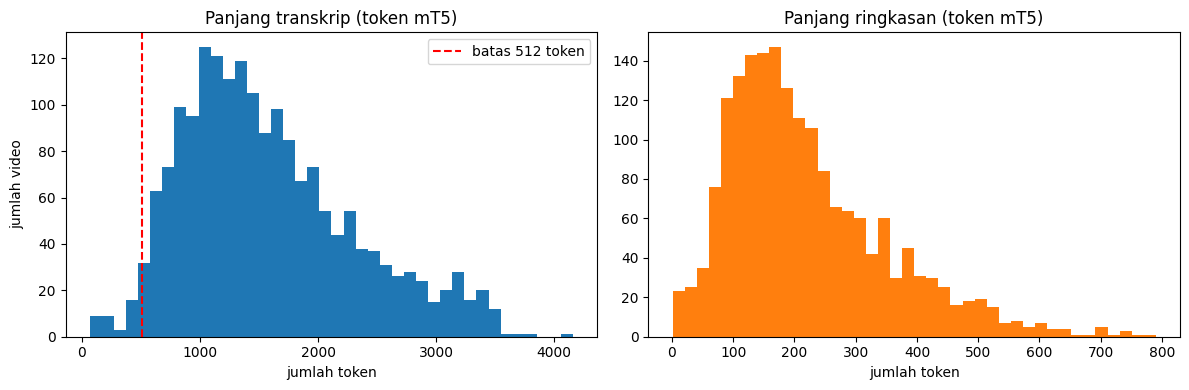

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(data_panjang['token_transkrip'], bins=40)
axes[0].axvline(512, color='red', linestyle='--', label='batas 512 token')
axes[0].set_title('Panjang transkrip (token mT5)')
axes[0].set_xlabel('jumlah token')
axes[0].set_ylabel('jumlah video')
axes[0].legend()

axes[1].hist(data_panjang['token_ringkasan'], bins=40, color='tab:orange')
axes[1].set_title('Panjang ringkasan (token mT5)')
axes[1].set_xlabel('jumlah token')

plt.tight_layout()
plt.savefig(f'{output_tahap1}/distribusi_panjang.png', dpi=150)
plt.show()

### 4.2 Anomali panjang
Dua jenis: ringkasan yang terlalu pendek (< 20 kata) dan ringkasan yang lebih panjang dari transkripnya.

In [14]:
ringkasan_terlalu_pendek = data_panjang[data_panjang['kata_ringkasan'] < 20]
print('Ringkasan < 20 kata:', len(ringkasan_terlalu_pendek))
ringkasan_terlalu_pendek.sort_values('kata_ringkasan')[['Video Name', 'kata_transkrip', 'kata_ringkasan', kolom_ringkasan]].head(20)

Ringkasan < 20 kata: 42


,Video Name,kata_transkrip,kata_ringkasan,Summary
475,Mechanism of E2 Reaction,624,1,test
455,Ethers,799,7,"In this lecture, I discuss ether compounds."
473,Zaitsev Elimination,804,7,"In this lecture, I discuss Zaitsev's Rule."
480,Transition State,1653,8,"In this lecture, I discuss the transition state."
1000,Pyrimidine Synthesis,972,8,This lecture will discuss the synthesis of pyr...
450,Acidity of Alcohols,529,9,"In this lecture, I discuss the acidity of alco..."
447,Organometallic Reagents,845,10,"In this lecture, I give an introduction to org..."
448,Nomenclature of Alcohols,1227,10,"In this lecture, I show you how to name alcohols."
454,Basicity of Amines,1176,10,"In this lecture, I discuss the basic propertie..."
467,Effect of Nucleophile on Sn1 Reaction,796,11,"In this lecture, I discuss how the nucleophile..."


In [15]:
ringkasan_lebih_panjang = data_panjang[data_panjang['kompresi_kata'] > 1]
print('Ringkasan lebih panjang dari transkrip:', len(ringkasan_lebih_panjang))
ringkasan_lebih_panjang.sort_values('kompresi_kata', ascending=False)[['Video Name', 'kata_transkrip', 'kata_ringkasan', kolom_transkrip]].head(10)

Ringkasan lebih panjang dari transkrip: 21


,Video Name,kata_transkrip,kata_ringkasan,Transcript
839,Structure of ATCase (Part II),49,286,and what that means is because we have more t...
709,Properties of Water and Hydrophobic Effect (Pa...,79,335,around the nonpolar substance and allows them...
718,Biological Buffer Systems (Part II),69,287,basically remain. And that's exactly why we u...
923,Gluconeogenesis (Steps 3-10) - Part II,103,278,So it's so in phosphate molecules. So we see ...
905,Stage 2 of Glycolysis (Part II),64,162,"is into steps. First, this step takes place a..."
234,Blood Clotting Cascade (Part II),152,380,"with factor 10, it activates factor 8 to comb..."
18,ABO Blood Types (Part II),163,339,"And so does IB, lower case IO. Now, what abou..."
726,Primary Structure of Proteins (Part II),141,281,those rotations will actually lead to stair h...
842,Covalent Modification and Phosphorylation (Par...,97,193,So it amplifies the effects and amplifies the...
781,Sanger Sequencing of DNA (Part II),245,441,of nucleotides following the primer. So we ha...


## 5. Uji terjemahan EN→ID (3 model kandidat)

Kandidat: `Helsinki-NLP/opus-mt-en-id`, `facebook/m2m100_418M`, `facebook/nllb-200-distilled-600M`.
Diterjemahkan **per kalimat** karena model dilatih pada kalimat pendek. Untuk uji cepat, transkrip diambil 15 kalimat pertama saja.

### 5.1 Cek panjang kalimat
Transkrip berasal dari ucapan lisan, jadi ada kalimat yang sangat panjang tanpa titik. Kalimat yang melebihi 256 token akan **terpotong diam-diam** saat diterjemahkan, jadi perlu dicek dulu berapa banyak.

In [16]:
def pecah_kalimat(teks):
    return [kalimat for kalimat in re.split(r'(?<=[.!?])\s+', str(teks).strip()) if kalimat]

tokenizer_opus = AutoTokenizer.from_pretrained('Helsinki-NLP/opus-mt-en-id')

semua_kalimat = [kalimat for teks in data_panjang[kolom_transkrip] for kalimat in pecah_kalimat(teks)]
panjang_kalimat = pd.Series([len(ids) for ids in tokenizer_opus(semua_kalimat)['input_ids']])

print('Jumlah kalimat:', len(semua_kalimat))
print(panjang_kalimat.describe(percentiles=[.5, .95, .99]).round(1))
print(f'Kalimat > 256 token: {(panjang_kalimat > 256).sum()} ({(panjang_kalimat > 256).mean() * 100:.2f}%)')
print('\nContoh kalimat terpanjang (300 karakter awal):')
print(semua_kalimat[panjang_kalimat.idxmax()][:300])

config.json:   0%|          | 0.00/1.38k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/796k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/801k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.26M [00:00<?, ?B/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (809 > 512). Running this sequence through the model will result in indexing errors


Jumlah kalimat: 99292
count    99292.0
mean        26.4
std         23.9
min          2.0
50%         23.0
95%         54.0
99%         78.0
max       1675.0
dtype: float64
Kalimat > 256 token: 56 (0.06%)

Contoh kalimat terpanjang (300 karakter awal):
So in step number one in order to promote and increase the specificity of the reaction and decrease the number of unwanted products from actually forming we have to use these different types of molecules to direct the correct synthesis of the protein because remember in any given amino acid we have 


### 5.2 Fungsi terjemahan
m2m100 dan NLLB perlu diberi tahu bahasa asal dan tujuan; opus-mt tidak perlu karena memang khusus EN→ID.

In [17]:
import torch
from transformers import AutoModelForSeq2SeqLM

device = 'cuda' if torch.cuda.is_available() else 'cpu'

kandidat_model_terjemahan = {
    'opusmt': 'Helsinki-NLP/opus-mt-en-id',
    'm2m100': 'facebook/m2m100_418M',
    'nllb': 'facebook/nllb-200-distilled-600M',
}

def muat_model_terjemahan(nama_model):
    tokenizer = AutoTokenizer.from_pretrained(nama_model)
    model = AutoModelForSeq2SeqLM.from_pretrained(nama_model).to(device).eval()
    pengaturan_bahasa = {}
    if 'm2m100' in nama_model:
        tokenizer.src_lang = 'en'
        pengaturan_bahasa['forced_bos_token_id'] = tokenizer.get_lang_id('id')
    elif 'nllb' in nama_model:
        tokenizer.src_lang = 'eng_Latn'
        pengaturan_bahasa['forced_bos_token_id'] = tokenizer.convert_tokens_to_ids('ind_Latn')
    return tokenizer, model, pengaturan_bahasa

@torch.no_grad()
def terjemahkan(daftar_kalimat, tokenizer, model, pengaturan_bahasa, ukuran_batch=32):
    hasil = []
    for i in range(0, len(daftar_kalimat), ukuran_batch):
        batch = tokenizer(daftar_kalimat[i:i + ukuran_batch], return_tensors='pt',
                          padding=True, truncation=True, max_length=256).to(device)
        # pakai max_length saja (bukan max_new_tokens) supaya tidak muncul warning berulang
        keluaran = model.generate(**batch, num_beams=4, max_length=256, **pengaturan_bahasa)
        hasil += tokenizer.batch_decode(keluaran, skip_special_tokens=True)
    return hasil

### 5.3 Jalankan pada sampel yang sama untuk ketiga model
Hasil diurutkan per sampel, jadi di spreadsheet tiga terjemahan dari teks yang sama letaknya berdekatan dan mudah dibandingkan.

In [18]:
# kalau sudah pernah dijalankan, hasil dibaca dari Drive (skor manual yang sudah diisi juga tidak tertimpa)
if uji_terjemahan_selesai:
    hasil_terjemahan = pd.read_csv(path_uji_terjemahan)
    print('Dibaca dari Drive:', path_uji_terjemahan)
else:
    jumlah_sampel = 60
    jumlah_kalimat_transkrip = 15
    sampel = data_panjang.sample(jumlah_sampel, random_state=42)

    semua_hasil = []
    for nama_singkat, nama_model in kandidat_model_terjemahan.items():
        tokenizer, model, pengaturan_bahasa = muat_model_terjemahan(nama_model)
        for indeks, baris in sampel.iterrows():
            kalimat_transkrip = pecah_kalimat(baris[kolom_transkrip])[:jumlah_kalimat_transkrip]
            kalimat_ringkasan = pecah_kalimat(baris[kolom_ringkasan])
            semua_hasil.append({
                'idx': indeks,
                'model': nama_singkat,
                'transkrip_en': ' '.join(kalimat_transkrip),
                'transkrip_id': ' '.join(terjemahkan(kalimat_transkrip, tokenizer, model, pengaturan_bahasa)),
                'ringkasan_en': baris[kolom_ringkasan],
                'ringkasan_id': ' '.join(terjemahkan(kalimat_ringkasan, tokenizer, model, pengaturan_bahasa)),
            })
        del model
        torch.cuda.empty_cache()
        print('Selesai:', nama_singkat)

    hasil_terjemahan = pd.DataFrame(semua_hasil).sort_values(['idx', 'model']).reset_index(drop=True)
    for kolom_isian in ['skor_makna', 'skor_istilah', 'skor_kealamian', 'catatan']:
        hasil_terjemahan[kolom_isian] = ''   # diisi manual, skala 1-3
    hasil_terjemahan.to_csv(path_uji_terjemahan, index=False)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  291MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  291MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

... (24 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.46GB            

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Selesai: nllb


In [19]:
# Lihat satu contoh ringkasan dari ketiga model berdampingan
contoh_idx = hasil_terjemahan['idx'].iloc[0]
print('[EN]', hasil_terjemahan.loc[hasil_terjemahan['idx'] == contoh_idx, 'ringkasan_en'].iloc[0][:400], '\n')
for _, baris in hasil_terjemahan[hasil_terjemahan['idx'] == contoh_idx].iterrows():
    print(f"[{baris['model']}] {baris['ringkasan_id'][:400]}\n")

[EN] Bacterial cells do not undergo meiosis but rather an asexual reproduction process known as binary fission. Binary fission produces two identical daughter cells, which implies that there is no genetic recombination taking place in binary fission. Instead, the bacterial cells depend on three different processes to recombine their genetic information. These processes are conjugation, transformation a 

[m2m100] Sel-sel bakteri tidak mengalami meiosis tetapi proses reproduksi asexual yang dikenal sebagai fisi biner. Fisi biner menghasilkan dua sel anak yang identik, yang berarti tidak ada rekombinasi genetik yang terjadi dalam fisi biner. Sebaliknya, sel-sel bakteri bergantung pada tiga proses yang berbeda untuk menggabungkan informasi genetik mereka. Proses ini adalah konjugasi, transformasi dan transduk

[nllb] Sel bakteri tidak mengalami meiosis melainkan proses reproduksi aseksual yang dikenal sebagai fisi biner. Fisi biner menghasilkan dua sel putri yang identik, yang berarti bah

In [20]:
hasil = pd.read_csv(f'{output_tahap1}/uji_terjemahan_3model.csv')
kata_melayu = r'\b(sahaja|nombor|kapilari|sebaik|kerana|daripada pada)\b'
kata_inggris = r'\b(the|of|and|which|that|is|are)\b'

cek = hasil.assign(
    artefak_spasi = hasil['ringkasan_id'].str.count(r'\w - \w') + hasil['transkrip_id'].str.count(r'\w - \w'),
    kata_melayu   = hasil['ringkasan_id'].str.count(kata_melayu, flags=re.I) + hasil['transkrip_id'].str.count(kata_melayu, flags=re.I),
    sisa_inggris  = hasil['ringkasan_id'].str.count(kata_inggris, flags=re.I) + hasil['transkrip_id'].str.count(kata_inggris, flags=re.I),
    rasio_panjang = hasil['ringkasan_id'].str.split().str.len() / hasil['ringkasan_en'].str.split().str.len(),
)
cek.groupby('model')[['artefak_spasi', 'kata_melayu', 'sisa_inggris', 'rasio_panjang']].agg(['sum', 'mean']).round(2)

artefak_spasi       kata_melayu       sisa_inggris       rasio_panjang  \
                 sum  mean         sum  mean          sum  mean           sum   
model                                                                           
m2m100             4  0.07          16  0.27            1  0.02         50.71   
nllb               4  0.07           0  0.00            1  0.02         50.08   
opusmt            37  0.62           0  0.00            6  0.10         50.63   

              
        mean  
model         
m2m100  0.85  
nllb    0.83  
opusmt  0.84

# Tahap 2: Cleaning & split

In [21]:
data_bersih = pd.read_csv(csv_path).drop(columns=['Unnamed: 0'])
riwayat_cleaning = [('Data awal', len(data_bersih))]

# 1) Normalisasi spasi: hapus spasi ganda, tab, newline, spasi di awal/akhir
def rapikan_spasi(teks):
    return re.sub(r'\s+', ' ', str(teks)).strip()

for kolom in [kolom_transkrip, kolom_ringkasan]:
    data_bersih[kolom] = data_bersih[kolom].where(data_bersih[kolom].isna(), data_bersih[kolom].map(rapikan_spasi))

# 2) Buang transkrip / ringkasan kosong
data_bersih = data_bersih[data_bersih[kolom_transkrip].notna() & data_bersih[kolom_ringkasan].notna()
                          & (data_bersih[kolom_transkrip] != '') & (data_bersih[kolom_ringkasan] != '')]
riwayat_cleaning.append(('Buang kosong', len(data_bersih)))

# 2b) Gabungkan Part I + Part II yang ringkasannya sama persis
def hapus_part(nama_video):
    return re.sub(r'[\s\-–:,]*\(?\bpart\s+([ivx]+|\d+)\b\)?\s*$', '', nama_video, flags=re.I).strip()

def nomor_part(nama_video):
    cocok = re.search(r'\bpart\s+([ivx]+|\d+)\b\)?\s*$', nama_video, flags=re.I)
    if not cocok:
        return 1                                   # judul tanpa "Part" dianggap bagian pertama
    nilai = cocok.group(1).lower()
    angka_romawi = {'i': 1, 'ii': 2, 'iii': 3, 'iv': 4, 'v': 5}
    return int(nilai) if nilai.isdigit() else angka_romawi.get(nilai, 99)

data_bersih['nama_tanpa_part'] = data_bersih['Video Name'].map(hapus_part)
data_bersih['nomor_part'] = data_bersih['Video Name'].map(nomor_part)

kunci_gabung = ['Course Name', 'Chapter', 'nama_tanpa_part', kolom_ringkasan]
ukuran_grup = data_bersih.groupby(kunci_gabung)[kolom_ringkasan].transform('size')
baris_digabung = data_bersih[ukuran_grup > 1].sort_values('nomor_part')

hasil_gabung = (baris_digabung.groupby(kunci_gabung, sort=False)
                .agg({kolom_transkrip: ' '.join, kolom_video: 'first', 'Video Name': list})
                .reset_index())
hasil_gabung['video_asal'] = hasil_gabung['Video Name'].map(' + '.join)
hasil_gabung['Video Name'] = hasil_gabung['nama_tanpa_part']

data_bersih = pd.concat([data_bersih[ukuran_grup == 1], hasil_gabung], ignore_index=True)
data_bersih = data_bersih.drop(columns=['nama_tanpa_part', 'nomor_part'])
riwayat_cleaning.append(('Gabung Part I + II (ringkasan sama)', len(data_bersih)))

# 3) Buang anomali: ringkasan < 20 kata ATAU ringkasan lebih panjang dari transkrip
data_bersih['kata_transkrip'] = data_bersih[kolom_transkrip].str.split().str.len()
data_bersih['kata_ringkasan'] = data_bersih[kolom_ringkasan].str.split().str.len()
data_bersih['kompresi'] = data_bersih['kata_ringkasan'] / data_bersih['kata_transkrip']
data_bersih = data_bersih[(data_bersih['kata_ringkasan'] >= 20) & (data_bersih['kompresi'] <= 1)]
riwayat_cleaning.append(('Buang anomali (ringkasan <20 kata / kompresi >1)', len(data_bersih)))

# 4) Buang SEMUA baris yang ringkasannya duplikat (tidak bisa dipastikan mana yang benar)
data_bersih = data_bersih[~data_bersih[kolom_ringkasan].duplicated(keep=False)]
riwayat_cleaning.append(('Buang ringkasan duplikat', len(data_bersih)))

# 5) Buang transkrip duplikat (jaga-jaga, harusnya 0)
data_bersih = data_bersih[~data_bersih[kolom_transkrip].duplicated(keep=False)]
riwayat_cleaning.append(('Buang transkrip duplikat', len(data_bersih)))

# 6) Grup topik: judul tanpa "(Part I)", "(Part II)", "Part 2", dst.
#    Part I dan Part II dari topik yang sama harus masuk split yang sama
def buat_grup_topik(baris):
    nama_video = re.sub(r'[\s\-–:,]*\(?\bpart\s+([ivx]+|\d+)\b\)?\s*$', '', baris['Video Name'], flags=re.I)
    return f"{baris['Course Name']} | {baris['Chapter']} | {nama_video.strip().lower()}"

data_bersih['grup_topik'] = data_bersih.apply(buat_grup_topik, axis=1)
data_bersih = data_bersih.reset_index(drop=True)

print(pd.DataFrame(riwayat_cleaning, columns=['Langkah', 'Sisa baris']).to_string(index=False))
print('\nJumlah grup topik:', data_bersih['grup_topik'].nunique())

                                         Langkah  Sisa baris
                                       Data awal        1871
                                    Buang kosong        1842
             Gabung Part I + II (ringkasan sama)        1802
Buang anomali (ringkasan <20 kata / kompresi >1)        1759
                        Buang ringkasan duplikat        1749
                        Buang transkrip duplikat        1749

Jumlah grup topik: 1741


In [22]:
hasil_penggabungan = data_bersih[data_bersih['video_asal'].notna()]
print('Baris hasil penggabungan:', len(hasil_penggabungan))
hasil_penggabungan[['video_asal', 'kata_transkrip', 'kata_ringkasan', 'kompresi']].sort_values('kompresi')

Baris hasil penggabungan: 39


,video_asal,kata_transkrip,kata_ringkasan,kompresi
1737,Enzyme Kinetics of Reversible Inhibition + Enz...,2833,73,0.025768
1716,Pedigree Analysis for Autosomal Dominant Trait...,2216,74,0.033394
1723,"Electrocyclic Reaction of 1,3,5 Hexatriene + E...",2175,89,0.040920
1731,Overview of Glycolysis + Overview of Glycolysi...,2381,98,0.041159
1712,Non-Linked Genes and Offspring Distribution + ...,2345,97,0.041365
1728,Fatty Acids + Fatty Acids (Part II),2638,124,0.047005
1724,Nernst Equation (Part I) + Nernst Equation (Pa...,1607,76,0.047293
1744,Step 1 of Citric Acid Cycle + Step 1 of Citric...,2325,122,0.052473
1722,Neuron Cells (Part I) + Neuron Cells (Part II),1409,75,0.053229
1717,"Gene Mapping, Percent Recombination and Map Un...",2012,111,0.055169


In [23]:
# Cek manual 3 hasil gabungan dengan kompresi terendah: apakah ringkasan mencakup kedua part?
contoh_gabungan = hasil_penggabungan.sort_values('kompresi').head(3)

for _, baris in contoh_gabungan.iterrows():
    print('=' * 100)
    for nama_part in baris['video_asal'].split(' + '):
        transkrip_part = str(df.loc[df['Video Name'] == nama_part, kolom_transkrip].iloc[0])
        print(f'[{nama_part}] {len(transkrip_part.split())} kata\n  awal: {transkrip_part[:200]}...\n')
    print('RINGKASAN:', baris[kolom_ringkasan], '\n')

[Enzyme Kinetics of Reversible Inhibition] 2117 kata
  awal:  Previously, we discussed the concept of enzyme inhibition, and we said there are two categories of enzyme inhibitors. We have irreversible enzyme inhibitors that bind onto the enzymes and don't let g...

[Enzyme Kinetics of Reversible Inhibition (Part II)] 716 kata
  awal:  and form into that product will not be as high. And that's exactly why the K-cat is lowered in the case in the presence of a non-competitive inhibitor. And finally, what about the K-M value? And this...

RINGKASAN: Since reversible inhibitors bind to enzymes and alter their activity, its only logical to assume that they will affect the kinetics of enzymes as well. Competitive inhibitors increase the Michaelis constant but do not change the maximal velocity and turnover number. Uncompetitive inhibitors decrease the maximal velocity and Michaelis constant but leave the turnover number the same. Noncompetitive inhibitors decrease the maximal velocity and tur

In [24]:
# Cek: grup yang berisi lebih dari 1 video (Part I/II yang tergabung)
grup_multi_video = data_bersih.groupby('grup_topik')['Video Name'].apply(list)
grup_multi_video = grup_multi_video[grup_multi_video.str.len() > 1]
print('Grup berisi >1 video:', len(grup_multi_video))
display(grup_multi_video.head(10))

# Cek filler lisan (cuma dihitung, BELUM dibuang)
jumlah_filler = data_bersih[kolom_transkrip].str.count(r'\b(um+|uh+|erm)\b', flags=re.I)
print('Transkrip yang mengandung filler:', (jumlah_filler > 0).sum(),
      '| rata-rata per transkrip:', round(jumlah_filler.mean(), 2))
print(data_bersih[['kata_transkrip', 'kata_ringkasan', 'kompresi']].describe().round(2))

Grup berisi >1 video: 5


,Video Name
grup_topik,
Classical physics | Wave Motion | doppler effect for sound waves,"[Doppler Effect for Sound Waves (Part I), Dopp..."
General chemistry | Kinetic Molecular Theory and Chemical Reactions | rate determining step and rate law,"[Rate Determining Step and Rate Law - Part I, ..."
Organic chemistry | Addition Reactions | hydroboration reaction,"[Hydroboration Reaction - Part I, Hydroboratio..."
Organic chemistry | Addition Reactions | synthesis of alcohols examples,"[Synthesis of Alcohols Examples (Part I), Synt..."
Organic chemistry | Peptide Chemistry | determining protein structure,"[Determining Protein Structure (Part I), Deter..."


Transkrip yang mengandung filler: 7 | rata-rata per transkrip: 0.0
       kata_transkrip  kata_ringkasan  kompresi
count         1749.00         1749.00   1749.00
mean          1108.98          145.93      0.15
std            491.10           78.67      0.08
min            254.00           21.00      0.02
25%            741.00           87.00      0.09
50%           1022.00          130.00      0.13
75%           1394.00          189.00      0.19
max           3481.00          480.00      0.64


## Split 80/10/10 per grup topik

Setiap baris di dataset adalah video yang berbeda, jadi split "per video" sama saja dengan split per baris. Yang perlu dijaga adalah video **Part I / Part II** dari topik yang sama, karena isinya mirip. Karena itu split dilakukan per `grup_topik` dengan seed tetap.

`GroupShuffleSplit` membagi berdasarkan jumlah grup, bukan jumlah baris, jadi proporsinya bisa sedikit meleset dari 80/10/10.

In [25]:
from sklearn.model_selection import GroupShuffleSplit

seed = 42

# Tahap 1: 80% train, 20% sisa
pemisah_pertama = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
indeks_train, indeks_sisa = next(pemisah_pertama.split(data_bersih, groups=data_bersih['grup_topik']))
data_sisa = data_bersih.iloc[indeks_sisa]

# Tahap 2: 20% sisa dibagi dua -> 10% val, 10% test
pemisah_kedua = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=seed)
indeks_dev, indeks_test = next(pemisah_kedua.split(data_sisa, groups=data_sisa['grup_topik']))

data_bersih['split'] = 'train'
data_bersih.loc[data_sisa.index[indeks_dev], 'split'] = 'val'
data_bersih.loc[data_sisa.index[indeks_test], 'split'] = 'test'

print(data_bersih['split'].value_counts())
print((data_bersih['split'].value_counts(normalize=True) * 100).round(1))

split
train    1399
val       175
test      175
Name: count, dtype: int64
split
train    80.0
val      10.0
test     10.0
Name: proportion, dtype: float64


In [26]:
# Bukti tidak ada kebocoran: tidak ada grup topik yang muncul di dua split
grup_per_split = {nama: set(data_bersih.loc[data_bersih['split'] == nama, 'grup_topik']) for nama in ['train', 'val', 'test']}
print('Irisan train-val :', len(grup_per_split['train'] & grup_per_split['val']))
print('Irisan train-test:', len(grup_per_split['train'] & grup_per_split['test']))
print('Irisan val-test  :', len(grup_per_split['val'] & grup_per_split['test']))

# Sebaran course per split (persen), supaya tiap split tidak didominasi satu course
display((pd.crosstab(data_bersih['Course Name'], data_bersih['split'], normalize='columns') * 100).round(1))

data_bersih.to_csv(f'{output_tahap2}/data_clean_en.csv', index=False)
print('Tersimpan:', f'{output_tahap2}/data_clean_en.csv')

Irisan train-val : 0
Irisan train-test: 0
Irisan val-test  : 0


split,test,train,val
Course Name,,,
Biochemistry,12.6,14.6,11.4
Biology,17.1,12.8,15.4
Classical physics,37.1,35.4,38.9
General chemistry,8.6,7.4,8.6
Modern physics,11.4,13.8,9.1
Organic chemistry,13.1,16.0,16.6


Tersimpan: /content/drive/MyDrive/DEEP_LEARNING_test/tahap2/data_clean_en.csv


# Tahap 3: Translasi penuh EN → ID dengan NLLB

Model dipilih berdasarkan uji 3 kandidat: NLLB satu-satunya yang bersih dari kata Melayu,
artefak spasi paling sedikit, dan istilah teknis paling tepat.
Penerjemahan dilakukan per kalimat. Progres disimpan ke Drive setiap blok,
sehingga kalau Colab terputus, proses bisa dilanjutkan dari blok terakhir.

In [27]:
data_clean_en = pd.read_csv(f'{output_tahap2}/data_clean_en.csv')
print('Ukuran data:', data_clean_en.shape)
print(data_clean_en['split'].value_counts())

Ukuran data: (1749, 12)
split
train    1399
val       175
test      175
Name: count, dtype: int64


Memuat Model NLLB

In [28]:
nama_model_terjemahan = 'facebook/nllb-200-distilled-600M'
device = 'cuda' if torch.cuda.is_available() else 'cpu'

if tahap3_selesai:
    print('NLLB tidak dimuat, data final sudah ada di Drive')
else:
    tokenizer_nllb = AutoTokenizer.from_pretrained(nama_model_terjemahan, src_lang='eng_Latn')
    model_nllb = AutoModelForSeq2SeqLM.from_pretrained(nama_model_terjemahan).half().to(device).eval()
    id_bahasa_tujuan = tokenizer_nllb.convert_tokens_to_ids('ind_Latn')

print('Device:', device)

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

Device: cuda


Fungsi-fungsi untuk Translasi

In [29]:
def pecah_kalimat(teks):
    return [kalimat for kalimat in re.split(r'(?<=[.!?])\s+', str(teks).strip()) if kalimat]

batas_kata_per_kalimat = 120

def pecah_kalimat_panjang(kalimat):
    # kalimat lisan yang sangat panjang dipotong per 120 kata supaya tidak terpotong diam-diam oleh max_length
    daftar_kata = kalimat.split()
    if len(daftar_kata) <= batas_kata_per_kalimat:
        return [kalimat]
    return [' '.join(daftar_kata[i:i + batas_kata_per_kalimat])
            for i in range(0, len(daftar_kata), batas_kata_per_kalimat)]

def rapikan_terjemahan(teks):
    teks = re.sub(r'(\w) - (\w)', r'\1-\2', teks)
    teks = re.sub(r'\s+([.,!?;:])', r'\1', teks)
    return re.sub(r'\s+', ' ', teks).strip()

@torch.no_grad()
def terjemahkan_nllb(daftar_kalimat, ukuran_batch=32):
    # urutkan dari yang terpendek supaya kalimat sepanjang mirip masuk batch yang sama (padding lebih sedikit)
    urutan = sorted(range(len(daftar_kalimat)), key=lambda i: len(daftar_kalimat[i]))
    hasil = [''] * len(daftar_kalimat)
    for awal in range(0, len(urutan), ukuran_batch):
        indeks_batch = urutan[awal:awal + ukuran_batch]
        batch = tokenizer_nllb([daftar_kalimat[i] for i in indeks_batch], return_tensors='pt',
                               padding=True, truncation=True, max_length=256).to(device)
        keluaran = model_nllb.generate(**batch, forced_bos_token_id=id_bahasa_tujuan,
                                       num_beams=4, max_length=256)
        for i, terjemahan in zip(indeks_batch, tokenizer_nllb.batch_decode(keluaran, skip_special_tokens=True)):
            hasil[i] = terjemahan
    return hasil


def terjemahkan_banyak_teks(daftar_teks):
    # kumpulkan kalimat dari banyak teks sekaligus, sambil mencatat asal teksnya
    semua_kalimat, asal_teks = [], []
    for nomor_teks, teks in enumerate(daftar_teks):
        for kalimat in pecah_kalimat(teks):
            for potongan in pecah_kalimat_panjang(kalimat):
                semua_kalimat.append(potongan)
                asal_teks.append(nomor_teks)

    hasil_kalimat = terjemahkan_nllb(semua_kalimat)

    # susun kembali per teks; urutan kalimat tetap karena asal_teks mengikuti urutan asli
    kalimat_per_teks = [[] for _ in daftar_teks]
    for nomor_teks, kalimat_id in zip(asal_teks, hasil_kalimat):
        kalimat_per_teks[nomor_teks].append(kalimat_id)
    return [rapikan_terjemahan(' '.join(kalimat)) for kalimat in kalimat_per_teks]

Uji Coba Kecil + Perkiraan Waktu

In [30]:
if tahap3_selesai:
    print('Dilewati, data final sudah ada di Drive')
else:
    contoh = data_clean_en.head(5)

    waktu_mulai = time.time()
    contoh_transkrip_id = terjemahkan_banyak_teks(contoh[kolom_transkrip].tolist())
    durasi = time.time() - waktu_mulai

    kata_contoh = contoh[kolom_transkrip].str.split().str.len().sum()
    kata_total = data_clean_en[kolom_transkrip].str.split().str.len().sum() + data_clean_en[kolom_ringkasan].str.split().str.len().sum()
    perkiraan_jam = durasi / kata_contoh * kata_total / 3600

    print(f'5 transkrip: {durasi:.0f} detik')
    print(f'Perkiraan seluruh data: ±{perkiraan_jam:.1f} jam')
    print('\n[EN]', contoh[kolom_transkrip].iloc[0][:400])
    print('\n[ID]', contoh_transkrip_id[0][:400])

5 transkrip: 20 detik
Perkiraan seluruh data: ±1.6 jam

[EN] Unlike most other systems of our body, the immune system is special because it is not localized to a specific region or a specific organ of the body instead, our immune system is spread out throughout the entire body it is found in many different regions of the body. Now as we'll see in the next several lectures, what the immune system does is it utilizes a serious of internal defense mechanisms t

[ID] Tidak seperti kebanyakan sistem tubuh lainnya, sistem kekebalan tubuh adalah khusus karena tidak lokalisasi ke wilayah tertentu atau organ tertentu dari tubuh, sistem kekebalan tubuh kita tersebar di seluruh tubuh dan ditemukan di banyak wilayah tubuh yang berbeda. Sekarang, seperti yang akan kita lihat dalam beberapa ceramah berikutnya, apa yang dilakukan oleh sistem kekebalan tubuh adalah menggu


Translasi Penuh dengan Checkpoint

In [31]:
path_progres = f'{output_tahap3}/progres_terjemahan.csv'
ukuran_blok = 20

if os.path.exists(path_progres):
    indeks_selesai = set(pd.read_csv(path_progres)['indeks'])
else:
    indeks_selesai = set()

data_belum = data_clean_en[~data_clean_en.index.isin(indeks_selesai)]
print(f'Sudah selesai: {len(indeks_selesai)} | sisa: {len(data_belum)}')

for awal in range(0, len(data_belum), ukuran_blok):
    blok = data_belum.iloc[awal:awal + ukuran_blok]
    hasil_blok = pd.DataFrame({
        'indeks': blok.index,
        'transkrip_id': terjemahkan_banyak_teks(blok[kolom_transkrip].tolist()),
        'ringkasan_id': terjemahkan_banyak_teks(blok[kolom_ringkasan].tolist()),
    })
    hasil_blok.to_csv(path_progres, mode='a', header=not os.path.exists(path_progres), index=False)
    print(f'{len(indeks_selesai) + awal + len(blok)} / {len(data_clean_en)} baris tersimpan')

Sudah selesai: 0 | sisa: 1749
20 / 1749 baris tersimpan
40 / 1749 baris tersimpan
60 / 1749 baris tersimpan
80 / 1749 baris tersimpan
100 / 1749 baris tersimpan
120 / 1749 baris tersimpan
140 / 1749 baris tersimpan
160 / 1749 baris tersimpan
180 / 1749 baris tersimpan
200 / 1749 baris tersimpan
220 / 1749 baris tersimpan
240 / 1749 baris tersimpan
260 / 1749 baris tersimpan
280 / 1749 baris tersimpan
300 / 1749 baris tersimpan
320 / 1749 baris tersimpan
340 / 1749 baris tersimpan
360 / 1749 baris tersimpan
380 / 1749 baris tersimpan
400 / 1749 baris tersimpan
420 / 1749 baris tersimpan
440 / 1749 baris tersimpan
460 / 1749 baris tersimpan
480 / 1749 baris tersimpan
500 / 1749 baris tersimpan
520 / 1749 baris tersimpan
540 / 1749 baris tersimpan
560 / 1749 baris tersimpan
580 / 1749 baris tersimpan
600 / 1749 baris tersimpan
620 / 1749 baris tersimpan
640 / 1749 baris tersimpan
660 / 1749 baris tersimpan
680 / 1749 baris tersimpan
700 / 1749 baris tersimpan
720 / 1749 baris tersimpan
74

Gabungkan dan Cek Kualitas

In [32]:
hasil_terjemahan_penuh = (pd.read_csv(path_progres)
                          .drop_duplicates('indeks', keep='last')
                          .set_index('indeks')
                          .sort_index())
data_clean_id = data_clean_en.join(hasil_terjemahan_penuh)

kata_inggris = r'\b(the|of|and|which|that|is|are)\b'
print('Baris belum diterjemahkan:', data_clean_id['transkrip_id'].isna().sum())
print('Sisa kata Inggris per transkrip:', data_clean_id['transkrip_id'].str.count(kata_inggris, flags=re.I).mean().round(2))
print('Artefak spasi tersisa:', data_clean_id['transkrip_id'].str.count(r'\w - \w').sum())

data_clean_id['rasio_panjang_id_en'] = (data_clean_id['transkrip_id'].str.split().str.len()
                                        / data_clean_id[kolom_transkrip].str.split().str.len())
print(data_clean_id['rasio_panjang_id_en'].describe().round(2))

Baris belum diterjemahkan: 0
Sisa kata Inggris per transkrip: 0.02
Artefak spasi tersisa: 0
count    1749.00
mean        0.87
std         0.03
min         0.76
25%         0.85
50%         0.87
75%         0.89
max         1.37
Name: rasio_panjang_id_en, dtype: float64


Cek Manual Hasil Terjemahan

In [33]:
# Bahan cek manual: 5 sampel acak + 5 baris dengan rasio panjang paling janggal
sampel_acak = data_clean_id.sample(5, random_state=42)
rasio_janggal = data_clean_id.sort_values('rasio_panjang_id_en').head(5)

for judul, kumpulan in [('SAMPEL ACAK', sampel_acak), ('RASIO PANJANG TERENDAH', rasio_janggal)]:
    print('#' * 100, f'\n{judul}\n')
    for indeks, baris in kumpulan.iterrows():
        print(f"[{indeks}] {baris['Video Name']} | rasio ID/EN = {baris['rasio_panjang_id_en']:.2f}")
        print('EN:', baris[kolom_ringkasan][:300])
        print('ID:', baris['ringkasan_id'][:300], '\n')

#################################################################################################### 
SAMPEL ACAK

[660] Ion Exchange Chromatography | rasio ID/EN = 0.87
EN: Ion-exchange chromatography, or simply ion chromatography, is a method that is used to purify a crude mixture of proteins based on their net charge. The setup for ion exchange chromatography is very similar to gel filtration chromatography. The only difference is the type of beads that are used. In 
ID: Kromatografi pertukaran ion, atau hanya kromatografi ion, adalah metode yang digunakan untuk memurnikan campuran mentah protein berdasarkan muatan bersih mereka. Konfigurasi untuk kromatografi pertukaran ion sangat mirip dengan kromatografi filtrasi gel. Satu-satunya perbedaan adalah jenis manik yan 

[1353] Intensity of Electromagnetic Waves | rasio ID/EN = 0.85
EN: In the previous lecture, we defined a concept known as the Poynting vector which gives us the energy transported per unit area per unit time at any ins

Cek Rasio Tertinggi dan Deteksi Pengulangan

In [34]:
def frasa_terbanyak(teks, panjang_frasa=4):
    # cari frasa 4 kata yang paling sering muncul; model yang "terjebak" akan mengulang frasa yang sama berkali-kali
    daftar_kata = str(teks).lower().split()
    hitungan = Counter(' '.join(daftar_kata[i:i + panjang_frasa]) for i in range(len(daftar_kata) - panjang_frasa + 1))
    return hitungan.most_common(1)[0] if hitungan else ('', 0)

data_clean_id['rasio_ringkasan_id_en'] = (data_clean_id['ringkasan_id'].str.split().str.len()
                                          / data_clean_id[kolom_ringkasan].str.split().str.len())
print('Rasio panjang ringkasan ID/EN:')
print(data_clean_id['rasio_ringkasan_id_en'].describe().round(2))

for kolom_en, kolom_id, kolom_rasio in [(kolom_transkrip, 'transkrip_id', 'rasio_panjang_id_en'),
                                        (kolom_ringkasan, 'ringkasan_id', 'rasio_ringkasan_id_en')]:
    print('\n' + '#' * 100, f'\nRASIO TERTINGGI: {kolom_id}\n')
    for indeks, baris in data_clean_id.sort_values(kolom_rasio, ascending=False).head(3).iterrows():
        frasa_id, jumlah_id = frasa_terbanyak(baris[kolom_id])
        frasa_en, jumlah_en = frasa_terbanyak(baris[kolom_en])
        print(f"[{indeks}] {baris['Video Name']} | rasio = {baris[kolom_rasio]:.2f}")
        print(f"  frasa terbanyak ID: '{frasa_id}' ({jumlah_id}x) | EN: '{frasa_en}' ({jumlah_en}x)")
        print('  ID:', baris[kolom_id][:300], '\n')

Rasio panjang ringkasan ID/EN:
count    1749.00
mean        0.82
std         0.06
min         0.59
25%         0.78
50%         0.82
75%         0.86
max         1.05
Name: rasio_ringkasan_id_en, dtype: float64

#################################################################################################### 
RASIO TERTINGGI: transkrip_id

[310] Vapor Pressure | rasio = 1.37
  frasa terbanyak ID: 'bertanggung jawab atas orang' (28x) | EN: 'the vapor pressure of' (3x)
  ID: Setiap kali kita berbicara tentang tekanan uap, kita berbicara tentang sistem tertutup, sistem tertutup adalah sistem di mana tidak ada massa yang memimpin sistem, jadi tidak ada molekul yang memimpin sistem. Sekarang kita juga berbicara tentang dua fase yang hadir dalam sistem, baik cair dan gas at 

[234] Chalcogen's and Noble Gases | rasio = 0.99
  frasa terbanyak ID: 'dalam ceramah ini, kita' (2x) | EN: 'in this lecture, we're' (2x)
  ID: Dalam ceramah ini, kita akan berbicara tentang dua kelompok atau keluarg

Terjemahkan ulang transkrip yang terjebak pengulangan (repetition loop)

In [35]:
indeks_bermasalah = [310]

@torch.no_grad()
def terjemahkan_tanpa_pengulangan(daftar_kalimat, ukuran_batch=32):
    hasil = []
    for awal in range(0, len(daftar_kalimat), ukuran_batch):
        batch = tokenizer_nllb(daftar_kalimat[awal:awal + ukuran_batch], return_tensors='pt',
                               padding=True, truncation=True, max_length=256).to(device)
        keluaran = model_nllb.generate(**batch, forced_bos_token_id=id_bahasa_tujuan, num_beams=4,
                                       max_length=256, no_repeat_ngram_size=3)
        hasil += tokenizer_nllb.batch_decode(keluaran, skip_special_tokens=True)
    return hasil

if tahap3_selesai:
    print('Dilewati, hasil terjemahan ulang [310] sudah tersimpan di data final')
else:
    for indeks in indeks_bermasalah:
        # tampilkan potongan yang bermasalah sebagai bukti (untuk slide / laporan)
        teks_lama = data_clean_id.loc[indeks, 'transkrip_id']
        frasa_lama, jumlah_lama = frasa_terbanyak(teks_lama)
        posisi = teks_lama.lower().find(frasa_lama)
        print(f'[{indeks}] SEBELUM: "{frasa_lama}" muncul {jumlah_lama}x')
        print('  potongan:', teks_lama[max(posisi - 150, 0):posisi + 350], '\n')

        # terjemahkan ulang semua kalimat transkrip ini dengan larangan pengulangan
        kalimat_en = [potongan for kalimat in pecah_kalimat(data_clean_id.loc[indeks, kolom_transkrip])
                      for potongan in pecah_kalimat_panjang(kalimat)]
        teks_baru = rapikan_terjemahan(' '.join(terjemahkan_tanpa_pengulangan(kalimat_en)))

        data_clean_id.loc[indeks, 'transkrip_id'] = teks_baru
        data_clean_id.loc[indeks, 'rasio_panjang_id_en'] = len(teks_baru.split()) / len(data_clean_id.loc[indeks, kolom_transkrip].split())

        frasa_baru, jumlah_baru = frasa_terbanyak(teks_baru)
        print(f'[{indeks}] SESUDAH: rasio = {data_clean_id.loc[indeks, "rasio_panjang_id_en"]:.2f} | '
              f'frasa terbanyak: "{frasa_baru}" ({jumlah_baru}x)')

[310] SEBELUM: "bertanggung jawab atas orang" muncul 28x
  potongan: am keadaan cair. Ikatan intermolekuler adalah ikatan, ikatan non-kovalen, yang memegang molekul bersama-sama dalam keadaan cair dan padat. Yang tidak bertanggung jawab atas orang yang tidak bertanggung jawab atas orang yang tidak bertanggung jawab atas orang yang tidak bertanggung jawab atas orang yang tidak bertanggung jawab atas orang yang tidak bertanggung jawab atas orang yang tidak bertanggung jawab atas orang yang tidak bertanggung jawab atas orang yang tidak bertanggung jawab atas orang y 

[310] SESUDAH: rasio = 0.96 | frasa terbanyak: "tekanan yang diberikan oleh" (2x)


Perbaiki Istilah

In [36]:
# Perbaikan istilah yang salah terjemah secara konsisten
pengganti_istilah = {
    r'\bceramah\b': 'kuliah',
    r'\blapisan kuman\b': 'lapisan germinal',
    r'\bkonstan gravitasi\b': 'konstanta gravitasi',
}

for pola, pengganti in pengganti_istilah.items():
    for kolom_id in ['transkrip_id', 'ringkasan_id']:
        jumlah = data_clean_id[kolom_id].str.count(pola, flags=re.I).sum()
        data_clean_id[kolom_id] = data_clean_id[kolom_id].str.replace(pola, pengganti, flags=re.I, regex=True)
        print(f"{kolom_id:13} | '{pola}' -> '{pengganti}': {jumlah} kemunculan diganti")

transkrip_id  | '\bceramah\b' -> 'kuliah': 1510 kemunculan diganti
ringkasan_id  | '\bceramah\b' -> 'kuliah': 306 kemunculan diganti
transkrip_id  | '\blapisan kuman\b' -> 'lapisan germinal': 33 kemunculan diganti
ringkasan_id  | '\blapisan kuman\b' -> 'lapisan germinal': 6 kemunculan diganti
transkrip_id  | '\bkonstan gravitasi\b' -> 'konstanta gravitasi': 32 kemunculan diganti
ringkasan_id  | '\bkonstan gravitasi\b' -> 'konstanta gravitasi': 8 kemunculan diganti


Profiling Ulang dan Simpan Hasil

In [37]:
if tahap3_selesai:
    # data final (sudah termasuk perbaikan [310] dan istilah) dibaca ulang, tidak ditimpa
    data_clean_id = pd.read_csv(path_data_id)
    print('Dibaca dari Drive:', path_data_id, '\n')
else:
    tokenizer_mt5 = AutoTokenizer.from_pretrained('google/mt5-small')

    token_transkrip_id = tokenizer_mt5(data_clean_id['transkrip_id'].tolist(), add_special_tokens=False)['input_ids']
    token_ringkasan_id = tokenizer_mt5(data_clean_id['ringkasan_id'].tolist(), add_special_tokens=False)['input_ids']
    data_clean_id['token_transkrip_id'] = [len(ids) for ids in token_transkrip_id]
    data_clean_id['token_ringkasan_id'] = [len(ids) for ids in token_ringkasan_id]

    data_clean_id.to_csv(path_data_id, index=False)
    print('Tersimpan:', path_data_id, '\n')

print(data_clean_id[['token_transkrip_id', 'token_ringkasan_id']].describe(percentiles=[.25, .5, .75, .95]).T.round(1))
print(f"\nTranskrip ID > 512 token: {(data_clean_id['token_transkrip_id'] > 512).mean() * 100:.1f}%")
for batas in [256, 384, 512]:
    print(f"Ringkasan ID utuh di batas {batas}: {(data_clean_id['token_ringkasan_id'] <= batas).mean() * 100:.1f}%")

Tersimpan: /content/drive/MyDrive/DEEP_LEARNING_test/tahap3/data_clean_id.csv 

                     count    mean    std    min     25%     50%     75%  \
token_transkrip_id  1749.0  1608.3  732.2  345.0  1060.0  1458.0  2022.0   
token_ringkasan_id  1749.0   216.2  121.5   30.0   127.0   189.0   281.0   

                       95%     max  
token_transkrip_id  3044.0  5307.0  
token_ringkasan_id   459.2   790.0  

Transkrip ID > 512 token: 99.0%
Ringkasan ID utuh di batas 256: 69.9%
Ringkasan ID utuh di batas 384: 89.7%
Ringkasan ID utuh di batas 512: 97.7%


# Tahap 4: Evaluasi ROUGE dan Baseline Ekstraktif

Dua baseline ekstraktif (memilih kalimat dari transkrip, tanpa training):
- **Lead-k**: ambil k kalimat pertama
- **TextRank**: ambil k kalimat paling "sentral" berdasarkan kemiripan antar kalimat

Nilai k dipilih menggunakan set **val**, lalu skor akhir dilaporkan pada set **test**.

In [38]:
data_clean_id = pd.read_csv(f'{output_tahap3}/data_clean_id.csv')
data_val = data_clean_id[data_clean_id['split'] == 'val'].reset_index(drop=True)
data_test = data_clean_id[data_clean_id['split'] == 'test'].reset_index(drop=True)

print('Val :', len(data_val))
print('Test:', len(data_test))

Val : 175
Test: 175


## Fungsi evaluasi ROUGE
ROUGE mengukur seberapa banyak kata/frasa ringkasan prediksi yang juga ada di ringkasan referensi.
- ROUGE-1: kesamaan kata tunggal
- ROUGE-2: kesamaan pasangan kata berurutan (bigram)
- ROUGE-L: kesamaan urutan kata terpanjang (longest common subsequence)

Stemmer dimatikan karena stemmer bawaan library hanya untuk bahasa Inggris.

In [39]:
penilai_rouge = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=False)

def hitung_rouge(daftar_prediksi, daftar_referensi):
    skor_per_sampel = [penilai_rouge.score(referensi, prediksi)
                       for prediksi, referensi in zip(daftar_prediksi, daftar_referensi)]
    return {
        'rouge1': np.mean([skor['rouge1'].fmeasure for skor in skor_per_sampel]) * 100,
        'rouge2': np.mean([skor['rouge2'].fmeasure for skor in skor_per_sampel]) * 100,
        'rougeL': np.mean([skor['rougeL'].fmeasure for skor in skor_per_sampel]) * 100,
        'panjang_kata': np.mean([len(str(prediksi).split()) for prediksi in daftar_prediksi]),
    }

# Uji kewajaran: referensi vs dirinya sendiri harus 100, referensi vs referensi video lain harus rendah
referensi_val = data_val['ringkasan_id'].tolist()
print('Referensi vs dirinya sendiri:', hitung_rouge(referensi_val, referensi_val))
print('Referensi vs video lain     :', hitung_rouge(referensi_val[1:] + referensi_val[:1], referensi_val))

Referensi vs dirinya sendiri: {'rouge1': np.float64(100.0), 'rouge2': np.float64(100.0), 'rougeL': np.float64(100.0), 'panjang_kata': np.float64(120.8)}
Referensi vs video lain     : {'rouge1': np.float64(22.705034900444147), 'rouge2': np.float64(4.156965181019755), 'rougeL': np.float64(12.96638443029484), 'panjang_kata': np.float64(120.8)}


## Baseline 1: Lead-k
Mengambil k kalimat pertama transkrip. Dasar pemikirannya: dosen biasanya membuka kuliah dengan
pengantar dan gambaran besar topik.

Lead-k dan Pemilihan k di Set Val

In [40]:
def pecah_kalimat(teks):
    return [kalimat for kalimat in re.split(r'(?<=[.!?])\s+', str(teks).strip()) if kalimat]

def ringkas_lead_k(teks, k):
    return ' '.join(pecah_kalimat(teks)[:k])

kandidat_k = [3, 5, 7, 9, 12, 15]

hasil_pemilihan_lead = []
for k in kandidat_k:
    prediksi_val = [ringkas_lead_k(teks, k) for teks in data_val['transkrip_id']]
    hasil_pemilihan_lead.append({'k': k, **hitung_rouge(prediksi_val, referensi_val)})

tabel_lead = pd.DataFrame(hasil_pemilihan_lead)
tabel_lead['rata_rata'] = tabel_lead[['rouge1', 'rouge2', 'rougeL']].mean(axis=1)
display(tabel_lead.round(2))

k_lead = int(tabel_lead.loc[tabel_lead['rata_rata'].idxmax(), 'k'])
print('k terbaik untuk Lead-k:', k_lead)

,k,rouge1,rouge2,rougeL,panjang_kata,rata_rata
0,3,29.58,10.48,18.90,58.87,19.65
1,5,35.64,12.64,21.83,96.65,23.37
2,7,37.14,13.06,21.92,131.90,24.04
3,9,37.11,13.11,21.50,166.06,23.90
4,12,35.89,12.93,20.46,217.73,23.09
5,15,34.22,12.53,19.40,268.83,22.05


k terbaik untuk Lead-k: 7


## Baseline 2: TextRank
Setiap kalimat menjadi titik (node) dalam graf; bobot sisi = kemiripan TF-IDF antar kalimat.
PageRank memberi skor tinggi pada kalimat yang mirip dengan banyak kalimat lain (kalimat "inti").
k kalimat dengan skor tertinggi diambil, lalu disusun kembali sesuai urutan aslinya.

TextRank dan Pemilihan k di Set Val

In [41]:
def ringkas_textrank(teks, k):
    daftar_kalimat = pecah_kalimat(teks)
    if len(daftar_kalimat) <= k:
        return ' '.join(daftar_kalimat)

    matriks_tfidf = TfidfVectorizer().fit_transform(daftar_kalimat)
    kemiripan = cosine_similarity(matriks_tfidf)
    np.fill_diagonal(kemiripan, 0)                       # kalimat tidak dihitung mirip dengan dirinya sendiri

    skor_kalimat = nx.pagerank(nx.from_numpy_array(kemiripan))
    indeks_terpilih = sorted(sorted(skor_kalimat, key=skor_kalimat.get, reverse=True)[:k])
    return ' '.join(daftar_kalimat[i] for i in indeks_terpilih)

hasil_pemilihan_textrank = []
for k in kandidat_k:
    prediksi_val = [ringkas_textrank(teks, k) for teks in data_val['transkrip_id']]
    hasil_pemilihan_textrank.append({'k': k, **hitung_rouge(prediksi_val, referensi_val)})

tabel_textrank = pd.DataFrame(hasil_pemilihan_textrank)
tabel_textrank['rata_rata'] = tabel_textrank[['rouge1', 'rouge2', 'rougeL']].mean(axis=1)
display(tabel_textrank.round(2))

k_textrank = int(tabel_textrank.loc[tabel_textrank['rata_rata'].idxmax(), 'k'])
print('k terbaik untuk TextRank:', k_textrank)

,k,rouge1,rouge2,rougeL,panjang_kata,rata_rata
0,3,32.97,9.35,18.98,102.64,20.43
1,5,34.83,10.46,19.62,152.69,21.64
2,7,34.48,10.84,19.00,202.30,21.44
3,9,33.23,10.66,18.36,247.42,20.75
4,12,31.32,10.80,17.53,310.45,19.88
5,15,29.40,10.62,16.77,369.97,18.93


k terbaik untuk TextRank: 5


Evaluasi Akhir di Set Test dan Simpan

In [42]:
referensi_test = data_test['ringkasan_id'].tolist()
prediksi_lead_test = [ringkas_lead_k(teks, k_lead) for teks in data_test['transkrip_id']]
prediksi_textrank_test = [ringkas_textrank(teks, k_textrank) for teks in data_test['transkrip_id']]

tabel_baseline = pd.DataFrame([
    {'metode': f'Lead-{k_lead}', **hitung_rouge(prediksi_lead_test, referensi_test)},
    {'metode': f'TextRank-{k_textrank}', **hitung_rouge(prediksi_textrank_test, referensi_test)},
]).round(2)
display(tabel_baseline)

tabel_baseline.to_csv(f'{output_tahap4}/skor_baseline_ekstraktif.csv', index=False)
data_test.assign(prediksi_lead=prediksi_lead_test, prediksi_textrank=prediksi_textrank_test)[
    ['Video Name', 'Course Name', 'ringkasan_id', 'prediksi_lead', 'prediksi_textrank']
].to_csv(f'{output_tahap4}/prediksi_baseline_test.csv', index=False)
print('Tersimpan di', output_tahap4)

,metode,rouge1,rouge2,rougeL,panjang_kata
0,Lead-7,37.66,13.52,21.79,126.82
1,TextRank-5,34.65,10.58,19.32,171.25


Tersimpan di /content/drive/MyDrive/DEEP_LEARNING_test/tahap4


Contoh Ringkasan

In [43]:
for indeks in [0, 1]:
    print('=' * 100)
    print('VIDEO     :', data_test.loc[indeks, 'Video Name'])
    print('\nREFERENSI :', data_test.loc[indeks, 'ringkasan_id'][:600])
    print(f'\nLEAD-{k_lead}    :', prediksi_lead_test[indeks][:600])
    print(f'\nTEXTRANK-{k_textrank}:', prediksi_textrank_test[indeks][:600], '\n')

VIDEO     : Alternative Pathway of Complement System

REFERENSI : Jalur lain dari sistem komplemen adalah jalur alternatif. Tidak seperti jalur klasik, jalur alternatif tidak memerlukan adanya kompleks antibodi-antigen untuk mengaktifkannya sendiri. Hal ini karena salah satu protein utama dari sistem komplemen, protein C3, dapat mengaktifkan dirinya sendiri secara spontan melalui proses hidrolisis. Dalam kondisi normal (tidak ada agen patogen), pemisahan spontan C3 menjadi C3a dan C3b bukanlah masalah karena sel sehat kita mengandung protein penghambat pada membran mereka yang dapat dengan cepat mengikat C3b dan menonaktifkannya. Namun, agen patogen seperti 

LEAD-7    : Seperti yang kita bahas sebelumnya, sistem komplemen sebenarnya terdiri dari dua jalur utama yang berbeda. Kami memiliki jalur klasik yang kami fokuskan sebelumnya, dan kami memiliki jalur alternatif yang akan kami fokuskan dalam kuliah ini. Jadi apa sebenarnya perbedaan utama antara dua jalur ini? Nah, seperti yang ki

# **Tahap 4 (bagian 2): Baseline 3 Zero-shot + Strategi Input Panjang**

## Baseline 3: Zero-shot T5
Model abstraktif `cahya/t5-base-indonesian-summarization-cased` (T5-base) yang sudah dilatih meringkas berita Liputan6,
dipakai langsung **tanpa fine-tuning** pada data kuliah. Baseline ini menunjukkan seberapa jauh model ringkasan umum
bisa dipakai di domain kuliah sebelum dilatih ulang.

Memuat Model Zero-shot

In [44]:
nama_model_zeroshot = 'cahya/t5-base-indonesian-summarization-cased'
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# tokenizer tetap dimuat karena dipakai untuk demo chunking
tokenizer_zeroshot = AutoTokenizer.from_pretrained(nama_model_zeroshot)

if zeroshot_selesai:
    print('Model tidak dimuat, prediksi zero-shot sudah ada di Drive')
else:
    # dimuat tanpa .half() karena T5 rawan menghasilkan NaN di fp16
    model_zeroshot = AutoModelForSeq2SeqLM.from_pretrained(nama_model_zeroshot).to(device).eval()
    print(f'Jumlah parameter: {model_zeroshot.num_parameters() / 1e6:.0f} juta')

print('Device:', device)

config.json:   0%|          | 0.00/657 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.07k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/793k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.79k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  892MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/260 [00:00<?, ?it/s]

Jumlah parameter: 223 juta
Device: cuda


## **Strategi Input Panjang: Truncation vs Chunk-and-summarize**
99% transkrip lebih panjang dari batas input model (512 token), jadi dibandingkan dua strategi:
- **Truncation**: hanya 512 token pertama yang dibaca model
- **Chunk-and-summarize**: transkrip dipecah per ±512 token tanpa memotong kalimat, tiap potongan diringkas, lalu gabungan ringkasannya diringkas sekali lagi

Fungsi menerima `model` dan `tokenizer` supaya bisa dipakai ulang untuk model hasil fine-tuning.

Fungsi-fungsi untuk Ringkasan dan Chunking

In [45]:
batas_token_input = 512

@torch.no_grad()
def ringkas_batch(daftar_teks, model, tokenizer, panjang_maks_ringkasan=256, ukuran_batch=8):
    # urutkan dari yang terpendek supaya teks sepanjang mirip masuk batch yang sama (padding lebih sedikit)
    urutan = sorted(range(len(daftar_teks)), key=lambda i: len(daftar_teks[i]))
    hasil = [''] * len(daftar_teks)
    for awal in range(0, len(urutan), ukuran_batch):
        indeks_batch = urutan[awal:awal + ukuran_batch]
        batch = tokenizer([daftar_teks[i] for i in indeks_batch], return_tensors='pt',
                          padding=True, truncation=True, max_length=batas_token_input).to(device)
        keluaran = model.generate(**batch, num_beams=4, max_new_tokens=panjang_maks_ringkasan,
                                  no_repeat_ngram_size=3, early_stopping=True)
        for i, ringkasan in zip(indeks_batch, tokenizer.batch_decode(keluaran, skip_special_tokens=True)):
            hasil[i] = ringkasan.strip()
    return hasil

def pecah_menjadi_chunk(teks, tokenizer, batas_token=batas_token_input - 2):
    # kalimat dikumpulkan sampai hampir 512 token, jadi potongan tidak memotong di tengah kalimat
    daftar_chunk, kalimat_chunk, jumlah_token_chunk = [], [], 0
    for kalimat in pecah_kalimat(teks):
        jumlah_token = len(tokenizer(kalimat, add_special_tokens=False)['input_ids'])
        if kalimat_chunk and jumlah_token_chunk + jumlah_token > batas_token:
            daftar_chunk.append(' '.join(kalimat_chunk))
            kalimat_chunk, jumlah_token_chunk = [], 0
        kalimat_chunk.append(kalimat)
        jumlah_token_chunk += jumlah_token
    if kalimat_chunk:
        daftar_chunk.append(' '.join(kalimat_chunk))
    return daftar_chunk

def ringkas_truncation(daftar_teks, model, tokenizer, panjang_maks_ringkasan=256):
    return ringkas_batch(daftar_teks, model, tokenizer, panjang_maks_ringkasan)

def ringkas_chunk_and_summarize(daftar_teks, model, tokenizer, panjang_maks_ringkasan=256):
    # kumpulkan chunk dari banyak teks sekaligus, sambil mencatat asal teksnya
    semua_chunk, asal_teks = [], []
    for nomor_teks, teks in enumerate(daftar_teks):
        for chunk in pecah_menjadi_chunk(teks, tokenizer):
            semua_chunk.append(chunk)
            asal_teks.append(nomor_teks)

    hasil_chunk = ringkas_batch(semua_chunk, model, tokenizer, panjang_maks_ringkasan)

    # susun kembali per teks; urutan chunk tetap karena asal_teks mengikuti urutan asli
    ringkasan_per_teks = [[] for _ in daftar_teks]
    for nomor_teks, ringkasan in zip(asal_teks, hasil_chunk):
        ringkasan_per_teks[nomor_teks].append(ringkasan)
    hasil = [' '.join(ringkasan) for ringkasan in ringkasan_per_teks]

    # gabungan ringkasan diringkas sekali lagi; teks yang hanya 1 chunk tidak perlu
    indeks_ulang = [i for i, ringkasan in enumerate(ringkasan_per_teks) if len(ringkasan) > 1]
    for i, ringkasan in zip(indeks_ulang, ringkas_batch([hasil[i] for i in indeks_ulang], model, tokenizer, panjang_maks_ringkasan)):
        hasil[i] = ringkasan
    return hasil

Demo Chunking pada Satu Transkrip

In [46]:
contoh_transkrip = data_test.loc[0, 'transkrip_id']
contoh_chunk = pecah_menjadi_chunk(contoh_transkrip, tokenizer_zeroshot)

print('VIDEO       :', data_test.loc[0, 'Video Name'])
print('Token total :', len(tokenizer_zeroshot(contoh_transkrip, add_special_tokens=False)['input_ids']))
print('Jumlah chunk:', len(contoh_chunk), '\n')
for nomor, chunk in enumerate(contoh_chunk, start=1):
    jumlah_token = len(tokenizer_zeroshot(chunk, add_special_tokens=False)['input_ids'])
    print(f'[chunk {nomor}] {jumlah_token} token | {chunk[:200]}\n')

VIDEO       : Alternative Pathway of Complement System
Token total : 1428
Jumlah chunk: 3 

[chunk 1] 492 token | Seperti yang kita bahas sebelumnya, sistem komplemen sebenarnya terdiri dari dua jalur utama yang berbeda. Kami memiliki jalur klasik yang kami fokuskan sebelumnya, dan kami memiliki jalur alternatif 

[chunk 2] 478 token | Sekarang, karena kita tidak memiliki sel sehat di dekatnya, kita hanya memiliki sel-sel bakteri, sel-sel bakteri itu tidak benar-benar memiliki protein penghambat ini untuk menonaktifkan tiga molekul 

[chunk 3] 458 token | Jadi, ini adalah loop umpan balik positif karena ini, yang terbentuk dalam proses B, dapat melanjutkan ke awal proses dan memperkuat pembentukan kompleks ini, yang kemudian dapat mengikuti proses A da



Sebaran Jumlah Chunk di Set Test

model.safetensors: reconstructing file:   0%|          |  0.00B /  892MB            

model.safetensors: downloading bytes:           |  0.00B            

count    175.00
mean       3.06
std        1.24
min        1.00
25%        2.00
50%        3.00
75%        4.00
max        7.00
Name: jumlah_chunk, dtype: float64


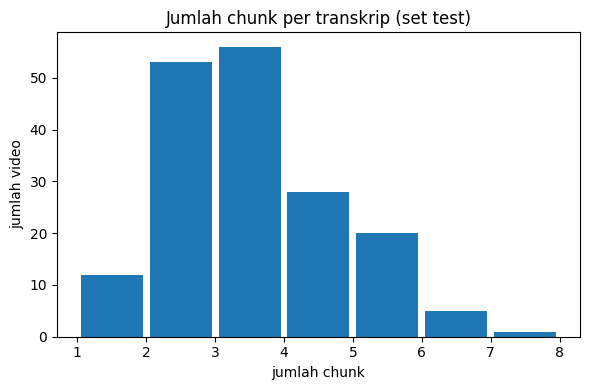

In [47]:
data_test['jumlah_chunk'] = [len(pecah_menjadi_chunk(teks, tokenizer_zeroshot)) for teks in data_test['transkrip_id']]
print(data_test['jumlah_chunk'].describe().round(2))

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(data_test['jumlah_chunk'], bins=range(1, data_test['jumlah_chunk'].max() + 2), rwidth=0.9)
ax.set_title('Jumlah chunk per transkrip (set test)')
ax.set_xlabel('jumlah chunk')
ax.set_ylabel('jumlah video')

plt.tight_layout()
plt.savefig(f'{output_tahap4}/sebaran_jumlah_chunk.png', dpi=150)
plt.show()

Evaluasi Akhir di Set Test dan Simpan

In [48]:
if zeroshot_selesai:
    prediksi_zeroshot = pd.read_csv(path_prediksi_zeroshot)
    prediksi_zeroshot_trunc_test = prediksi_zeroshot['prediksi_zeroshot_trunc'].fillna('').tolist()
    prediksi_zeroshot_chunk_test = prediksi_zeroshot['prediksi_zeroshot_chunk'].fillna('').tolist()
    print('Dibaca dari Drive:', path_prediksi_zeroshot)
else:
    daftar_transkrip_test = data_test['transkrip_id'].tolist()

    waktu_mulai = time.time()
    prediksi_zeroshot_trunc_test = ringkas_truncation(daftar_transkrip_test, model_zeroshot, tokenizer_zeroshot)
    print(f'Truncation         : {(time.time() - waktu_mulai) / 60:.1f} menit')

    waktu_mulai = time.time()
    prediksi_zeroshot_chunk_test = ringkas_chunk_and_summarize(daftar_transkrip_test, model_zeroshot, tokenizer_zeroshot)
    print(f'Chunk-and-summarize: {(time.time() - waktu_mulai) / 60:.1f} menit')

    data_test.assign(prediksi_zeroshot_trunc=prediksi_zeroshot_trunc_test, prediksi_zeroshot_chunk=prediksi_zeroshot_chunk_test)[
        ['Video Name', 'Course Name', 'jumlah_chunk', 'ringkasan_id', 'prediksi_zeroshot_trunc', 'prediksi_zeroshot_chunk']
    ].to_csv(path_prediksi_zeroshot, index=False)

tabel_baseline_lengkap = pd.concat([tabel_baseline, pd.DataFrame([
    {'metode': 'Zero-shot (truncation)', **hitung_rouge(prediksi_zeroshot_trunc_test, referensi_test)},
    {'metode': 'Zero-shot (chunk-and-summarize)', **hitung_rouge(prediksi_zeroshot_chunk_test, referensi_test)},
])], ignore_index=True).round(2)
display(tabel_baseline_lengkap)

tabel_baseline_lengkap.to_csv(f'{output_tahap4}/skor_baseline_lengkap.csv', index=False)
print('Tersimpan di', output_tahap4)

Truncation         : 1.9 menit
Chunk-and-summarize: 6.1 menit


,metode,rouge1,rouge2,rougeL,panjang_kata
0,Lead-7,37.66,13.52,21.79,126.82
1,TextRank-5,34.65,10.58,19.32,171.25
2,Zero-shot (truncation),27.60,9.94,18.07,45.19
3,Zero-shot (chunk-and-summarize),28.31,9.94,18.21,49.27


Tersimpan di /content/drive/MyDrive/DEEP_LEARNING_test/tahap4


Contoh Ringkasan Zero-shot

In [49]:
for indeks in [0, 1]:
    print('=' * 100)
    print('VIDEO     :', data_test.loc[indeks, 'Video Name'], f"({data_test.loc[indeks, 'jumlah_chunk']} chunk)")
    print('\nREFERENSI :', data_test.loc[indeks, 'ringkasan_id'][:600])
    print(f'\nLEAD-{k_lead}    :', prediksi_lead_test[indeks][:600])
    print('\nZS-TRUNC  :', prediksi_zeroshot_trunc_test[indeks][:600])
    print('\nZS-CHUNK  :', prediksi_zeroshot_chunk_test[indeks][:600], '\n')

VIDEO     : Alternative Pathway of Complement System (3 chunk)

REFERENSI : Jalur lain dari sistem komplemen adalah jalur alternatif. Tidak seperti jalur klasik, jalur alternatif tidak memerlukan adanya kompleks antibodi-antigen untuk mengaktifkannya sendiri. Hal ini karena salah satu protein utama dari sistem komplemen, protein C3, dapat mengaktifkan dirinya sendiri secara spontan melalui proses hidrolisis. Dalam kondisi normal (tidak ada agen patogen), pemisahan spontan C3 menjadi C3a dan C3b bukanlah masalah karena sel sehat kita mengandung protein penghambat pada membran mereka yang dapat dengan cepat mengikat C3b dan menonaktifkannya. Namun, agen patogen seperti 

LEAD-7    : Seperti yang kita bahas sebelumnya, sistem komplemen sebenarnya terdiri dari dua jalur utama yang berbeda. Kami memiliki jalur klasik yang kami fokuskan sebelumnya, dan kami memiliki jalur alternatif yang akan kami fokuskan dalam kuliah ini. Jadi apa sebenarnya perbedaan utama antara dua jalur ini? Nah, seper

# Tahap 5: Seleksi Model Utama

Tiga kandidat seq2seq di-fine-tune singkat dengan pengaturan yang sama, lalu dibandingkan untuk memilih satu model utama:
- **mT5-base** (`google/mt5-base`): multibahasa, tokenizer besar, dilatih tanpa fp16 karena rawan loss `NaN`
- **mBART-50** (`facebook/mbart-large-50`): multibahasa, ±610 juta parameter, perlu kode bahasa `id_ID`
- **IndoBART-v2** (`indobenchmark/indobart-v2`): khusus bahasa Indonesia, ±132 juta parameter, teks diproses dalam huruf kecil

Pengaturan uji: 300 baris train, 2 epoch, input 512 token (truncation), target 384 token, optimizer Adafactor supaya muat di GPU T4.
Learning rate mengikuti nilai umum tiap keluarga model dan belum di-tuning (tuning dilakukan di Tahap 6).
Yang dicatat per model: VRAM puncak, waktu per epoch, train loss dan val loss, ROUGE pada 50 transkrip val, dan contoh ringkasan.

Tokenizer resmi IndoBART (`IndoNLGTokenizer` dari paket `indobenchmark-toolkit`) tidak bisa di-import di transformers versi baru,
jadi dibuat tokenizer pengganti dengan format input dan label yang sama.

In [50]:
output_tahap5 = f'{folder_utama}/tahap5'
os.makedirs(output_tahap5, exist_ok=True)

# model zero-shot Tahap 4 (kalau sempat dimuat) dibuang dari GPU supaya memori cukup untuk fine-tuning
if 'model_zeroshot' in globals():
    del model_zeroshot
    gc.collect()
    torch.cuda.empty_cache()

seed = 42
jumlah_sampel_latih = 300
jumlah_sampel_rouge = 50
jumlah_epoch = 2
batas_token_ringkasan = 384

data_latih_seleksi = data_clean_id[data_clean_id['split'] == 'train'].sample(jumlah_sampel_latih, random_state=seed)
data_val_rouge = data_val.sample(jumlah_sampel_rouge, random_state=seed).reset_index(drop=True)

print('Data latih seleksi:', len(data_latih_seleksi))
print('Data val (loss)   :', len(data_val))
print('Data val (ROUGE)  :', len(data_val_rouge))

Data latih seleksi: 300
Data val (loss)   : 175
Data val (ROUGE)  : 50


Tokenizer Pengganti untuk IndoBART

In [51]:
class TokenizerIndoBART:
    # meniru IndoNLGTokenizer: teks dikecilkan, lalu format <s> teks </s> [indonesian] untuk input maupun label
    def __init__(self, nama_model):
        self.sp_model = spm.SentencePieceProcessor(model_file=hf_hub_download(nama_model, 'sentencepiece.bpe.model'))
        self.bos_token_id, self.pad_token_id, self.eos_token_id = 0, 1, 2
        self.id_bahasa = 40002   # token [indonesian]

    def __call__(self, teks=None, text_target=None, max_length=None, truncation=False, padding=False,
                 return_tensors=None, add_special_tokens=True):
        teks = text_target if text_target is not None else teks
        daftar_teks = [teks] if isinstance(teks, str) else list(teks)

        daftar_ids = []
        for satu_teks in daftar_teks:
            ids = self.sp_model.encode(str(satu_teks).lower())
            if add_special_tokens:
                if truncation and max_length:
                    ids = ids[:max_length - 3]
                ids = [self.bos_token_id] + ids + [self.eos_token_id, self.id_bahasa]
            daftar_ids.append(ids)

        daftar_mask = [[1] * len(ids) for ids in daftar_ids]
        if padding:
            panjang_maks = max(len(ids) for ids in daftar_ids)
            daftar_mask = [mask + [0] * (panjang_maks - len(mask)) for mask in daftar_mask]
            daftar_ids = [ids + [self.pad_token_id] * (panjang_maks - len(ids)) for ids in daftar_ids]

        if return_tensors == 'pt':
            return BatchEncoding({'input_ids': torch.tensor(daftar_ids), 'attention_mask': torch.tensor(daftar_mask)})
        if isinstance(teks, str):
            return {'input_ids': daftar_ids[0], 'attention_mask': daftar_mask[0]}
        return {'input_ids': daftar_ids, 'attention_mask': daftar_mask}

    def batch_decode(self, daftar_ids, skip_special_tokens=True):
        # id 0-3 (<s>, <pad>, </s>, <unk>) dan id >= 40000 (token bahasa, <mask>) dibuang
        return [self.sp_model.decode([int(i) for i in ids if 3 < int(i) < 40000]) for ids in daftar_ids]

Fungsi-fungsi untuk Seleksi Model

In [52]:
kandidat_model_utama = {
    'mt5': {'nama_model': 'google/mt5-base', 'learning_rate': 5e-4, 'fp16': False},
    'mbart': {'nama_model': 'facebook/mbart-large-50', 'learning_rate': 1e-4, 'fp16': True},
    'indobart': {'nama_model': 'indobenchmark/indobart-v2', 'learning_rate': 1e-4, 'fp16': True},
}

def muat_tokenizer(nama_model):
    if 'indobart' in nama_model:
        return TokenizerIndoBART(nama_model)
    if 'mbart' in nama_model:
        return AutoTokenizer.from_pretrained(nama_model, src_lang='id_ID', tgt_lang='id_ID')
    return AutoTokenizer.from_pretrained(nama_model)

def muat_kandidat(nama_model):
    tokenizer = muat_tokenizer(nama_model)
    model = AutoModelForSeq2SeqLM.from_pretrained(nama_model).to(device)

    # token awal ringkasan saat generate harus sama dengan format label saat training
    if 'indobart' in nama_model:
        model.generation_config.decoder_start_token_id = tokenizer.id_bahasa
        model.generation_config.forced_bos_token_id = tokenizer.bos_token_id
    elif 'mbart' in nama_model:
        model.generation_config.forced_bos_token_id = tokenizer.convert_tokens_to_ids('id_ID')
    return tokenizer, model

def tokenisasi_pasangan(data, tokenizer):
    daftar_input = tokenizer(data['transkrip_id'].tolist(), max_length=batas_token_input, truncation=True)['input_ids']
    daftar_label = tokenizer(text_target=data['ringkasan_id'].tolist(), max_length=batas_token_ringkasan, truncation=True)['input_ids']
    return [{'input_ids': input_ids, 'labels': label} for input_ids, label in zip(daftar_input, daftar_label)]

def buat_pengumpul_batch(id_padding):
    # padding ke panjang terpanjang di batch; padding label diisi -100 supaya tidak ikut dihitung di loss
    def gabungkan_batch(daftar_contoh):
        panjang_input = max(len(contoh['input_ids']) for contoh in daftar_contoh)
        panjang_label = max(len(contoh['labels']) for contoh in daftar_contoh)
        return {
            'input_ids': torch.tensor([contoh['input_ids'] + [id_padding] * (panjang_input - len(contoh['input_ids']))
                                       for contoh in daftar_contoh]),
            'attention_mask': torch.tensor([[1] * len(contoh['input_ids']) + [0] * (panjang_input - len(contoh['input_ids']))
                                            for contoh in daftar_contoh]),
            'labels': torch.tensor([contoh['labels'] + [-100] * (panjang_label - len(contoh['labels']))
                                    for contoh in daftar_contoh]),
        }
    return gabungkan_batch

Uji Coba Kecil Tokenizer

In [53]:
contoh_transkrip = data_latih_seleksi['transkrip_id'].iloc[0]
contoh_ringkasan = data_latih_seleksi['ringkasan_id'].iloc[0]

for nama_singkat, pengaturan in kandidat_model_utama.items():
    tokenizer = muat_tokenizer(pengaturan['nama_model'])
    contoh_token = tokenisasi_pasangan(data_latih_seleksi.head(1), tokenizer)[0]
    token_transkrip = len(tokenizer(contoh_transkrip, add_special_tokens=False)['input_ids'])
    print(f'[{nama_singkat}] token transkrip utuh: {token_transkrip} | input: {len(contoh_token["input_ids"])} | label: {len(contoh_token["labels"])}')
    print('  label didecode:', tokenizer.batch_decode([contoh_token['labels']], skip_special_tokens=True)[0][:150], '\n')

config.json:   0%|          | 0.00/702 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/376 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/4.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

[mt5] token transkrip utuh: 2132 | input: 512 | label: 72
  label didecode: Metabolisme glikogen terdiri dari dua proses-sintesis glikogen dan degradasi glikogen. Namun kedua proses ini tidak terjadi pada saat yang sama. Fakta 



config.json:   0%|          | 0.00/1.42k [00:00<?, ?B/s]

... (5 outputs left out)

[mbart] token transkrip utuh: 1792 | input: 512 | label: 64
  label didecode: Metabolisme glikogen terdiri dari dua proses-sintesis glikogen dan degradasi glikogen. Namun kedua proses ini tidak terjadi pada saat yang sama. Fakta 



sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  932kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

[indobart] token transkrip utuh: 1529 | input: 512 | label: 56
  label didecode: metabolisme glikogen terdiri dari dua proses-sintesis glikogen dan degradasi glikogen. namun kedua proses ini tidak terjadi pada saat yang sama. fakta 



Fine-tuning Singkat per Kandidat

Hasil tiap model disimpan ke Drive begitu selesai, jadi kalau Colab terputus, model yang sudah selesai tidak dilatih ulang.

In [54]:
path_hasil_seleksi = f'{output_tahap5}/hasil_seleksi_model.csv'

if os.path.exists(path_hasil_seleksi):
    model_selesai = set(pd.read_csv(path_hasil_seleksi)['model'])
else:
    model_selesai = set()

for nama_singkat, pengaturan in kandidat_model_utama.items():
    if nama_singkat in model_selesai:
        print('Sudah selesai, dilewati:', nama_singkat)
        continue

    tokenizer, model = muat_kandidat(pengaturan['nama_model'])
    argumen_latih = Seq2SeqTrainingArguments(
        output_dir=f'/content/seleksi_{nama_singkat}',
        num_train_epochs=jumlah_epoch,
        per_device_train_batch_size=2,
        per_device_eval_batch_size=2,
        gradient_accumulation_steps=4,
        learning_rate=pengaturan['learning_rate'],
        optim='adafactor',
        warmup_steps=10,
        fp16=pengaturan['fp16'],
        gradient_checkpointing=True,
        eval_strategy='epoch',
        save_strategy='no',
        logging_steps=5,
        report_to='none',
        seed=seed,
    )
    trainer = Seq2SeqTrainer(
        model=model,
        args=argumen_latih,
        train_dataset=tokenisasi_pasangan(data_latih_seleksi, tokenizer),
        eval_dataset=tokenisasi_pasangan(data_val, tokenizer),
        data_collator=buat_pengumpul_batch(tokenizer.pad_token_id),
    )

    torch.cuda.reset_peak_memory_stats()
    waktu_mulai = time.time()
    trainer.train()
    durasi_latih = time.time() - waktu_mulai
    vram_puncak = torch.cuda.max_memory_allocated() / 1024 ** 3

    riwayat_loss = pd.DataFrame(trainer.state.log_history)
    riwayat_loss.assign(model=nama_singkat).to_csv(f'{output_tahap5}/log_loss_{nama_singkat}.csv', index=False)

    # optimizer dibuang dulu dari GPU sebelum generate
    del trainer
    gc.collect()
    torch.cuda.empty_cache()

    model.eval()
    prediksi_val = ringkas_batch(data_val_rouge['transkrip_id'].tolist(), model, tokenizer)

    hasil_satu_model = pd.DataFrame([{
        'model': nama_singkat,
        'parameter_juta': model.num_parameters() / 1e6,
        'vram_puncak_gb': vram_puncak,
        'menit_per_epoch': durasi_latih / 60 / jumlah_epoch,
        'train_loss': riwayat_loss['loss'].dropna().iloc[-1],
        'val_loss': riwayat_loss['eval_loss'].dropna().iloc[-1],
        **hitung_rouge(prediksi_val, data_val_rouge['ringkasan_id'].tolist()),
    }])
    hasil_satu_model.to_csv(path_hasil_seleksi, mode='a', header=not os.path.exists(path_hasil_seleksi), index=False)
    data_val_rouge.assign(prediksi=prediksi_val)[['Video Name', 'ringkasan_id', 'prediksi']].to_csv(
        f'{output_tahap5}/prediksi_val_{nama_singkat}.csv', index=False)

    del model
    gc.collect()
    torch.cuda.empty_cache()
    print(f'Selesai: {nama_singkat} | VRAM puncak {vram_puncak:.1f} GB | {durasi_latih / 60:.1f} menit')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 2.33GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/284 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.33GB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


... (17 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  526MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch,Training Loss,Validation Loss
1,12.712930,3.081836
2,10.874978,2.901500


Selesai: indobart | VRAM puncak 2.7 GB | 0.8 menit


Perbandingan Kandidat

,model,parameter_juta,vram_puncak_gb,menit_per_epoch,train_loss,val_loss,rouge1,rouge2,rougeL,panjang_kata
0,mt5,582.40,7.82,2.83,13.62,2.72,22.37,7.24,14.87,38.82
1,mbart,610.88,8.46,1.28,9.27,2.66,32.35,12.94,21.48,44.56
2,indobart,131.54,2.71,0.41,10.87,2.90,33.87,12.31,21.81,58.90


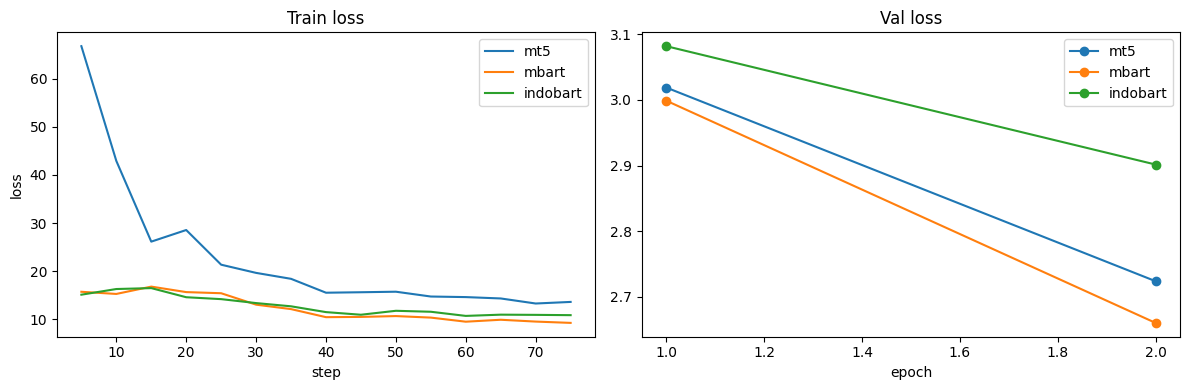

In [55]:
tabel_seleksi = pd.read_csv(path_hasil_seleksi).round(2)
display(tabel_seleksi)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for nama_singkat in tabel_seleksi['model']:
    riwayat_loss = pd.read_csv(f'{output_tahap5}/log_loss_{nama_singkat}.csv')
    loss_latih = riwayat_loss.dropna(subset=['loss'])
    loss_val = riwayat_loss.dropna(subset=['eval_loss'])
    axes[0].plot(loss_latih['step'], loss_latih['loss'], label=nama_singkat)
    axes[1].plot(loss_val['epoch'], loss_val['eval_loss'], marker='o', label=nama_singkat)

axes[0].set_title('Train loss')
axes[0].set_xlabel('step')
axes[0].set_ylabel('loss')
axes[0].legend()

axes[1].set_title('Val loss')
axes[1].set_xlabel('epoch')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{output_tahap5}/grafik_loss_seleksi.png', dpi=150)
plt.show()

Contoh Ringkasan

In [56]:
prediksi_per_model = {nama_singkat: pd.read_csv(f'{output_tahap5}/prediksi_val_{nama_singkat}.csv')
                      for nama_singkat in tabel_seleksi['model']}

for indeks in [0, 1]:
    print('=' * 100)
    print('VIDEO     :', data_val_rouge.loc[indeks, 'Video Name'])
    print('\nREFERENSI :', data_val_rouge.loc[indeks, 'ringkasan_id'][:600])
    for nama_singkat, prediksi in prediksi_per_model.items():
        print(f'\n{nama_singkat.upper():<10}:', str(prediksi.loc[indeks, 'prediksi'])[:600])
    print()

VIDEO     : Doppler Effect for Light

REFERENSI : Sama seperti suara, cahaya (bersama dengan semua bentuk radiasi elektromagnetik lainnya) mengalami pergeseran frekuensi ketika ada gerakan relatif antara sumber cahaya dan pengamat dan ini dikenal sebagai pergeseran Doppler. Karena cahaya tidak memerlukan media untuk menyebar, dengan teori relativitas khusus, kita tahu bahwa tidak ada cara untuk membedakan apakah sumber cahaya bergerak atau pengamat bergerak. Oleh karena itu, hanya ada dua persamaan yang menggambarkan Efek Doppler untuk cahaya (dibandingkan dengan empat persamaan untuk gelombang suara). Salah satu persamaan ini menggambarkan g

MT5       : <extra_id_0>, kita dapat menggambarkan gerak relatif dari gerakan pengamat dan gerakan sumber cahaya. Persamaan kedua adalah bahwa gelombang suara mengalami pergeseran antara sumber dan pengamat.

MBART     : Efek Doppler untuk cahaya adalah pergeseran frekuensi ketika ada gerakan relatif antara sumber cahaya dan pengamat. Persamaan i